# Multi-Region REE Prospectivity — No-Geochemistry (RF + DevNet) — v4

**What changed vs. the original notebook**

The original evaluation was dominated by noise: each region has only a
handful of positive (known-deposit) samples (Cordilleran 43, Superior 8,
Grenville 6), so a plain 5-fold CV reports one AUC per fold that is decided
almost entirely by the rank of a single positive sample, and the DevNet loss
injected fresh Gaussian noise into the reference distribution every batch,
making training unstable.

This version keeps every piece of the **data pipeline** (config, raster
clipping, feature extraction, GLCM, negative sampling, `build_region`,
`feature_matrix`, worm KDTrees) exactly as before, and replaces only the
**modeling, cross-validation and evaluation** code:

1. A corrected DevNet deviation loss with a fixed, large reference pool
   (no more `randn_like` resampled every batch), plus a pairwise ranking-loss
   alternative, switchable via `LOSS_TYPE`.
2. A smaller / more regularized network (`Linear→32→ReLU→Dropout(0.4)→Linear`,
   `weight_decay=1e-3`) since the old 64→32 net was heavily over-parameterized
   for a training set with single-digit positives.
3. A fold-safe evaluation protocol shared by RF and DevNet:
   - **Pooled out-of-fold (OOF) AUC/AP** with per-fold percentile-rank
     normalization before pooling (never averaging tiny per-fold AUCs).
   - **RepeatedStratifiedKFold** distribution of the pooled OOF AUC,
     reported as median + 95% interval instead of a single point estimate.
4. Random Forest is refit inside a `Pipeline(SimpleImputer→StandardScaler→RF)`
   so the imputer/scaler are fit *inside* each fold/repeat, removing the
   leakage in the original notebook (where they were fit once on all data).

Everything below is deterministic given the fixed seeds in the config cell.


---

## v3 changes (on top of v2)

Data pipeline, `feature_matrix`, and the core evaluation algorithms
(`pooled_oof_eval`, `repeated_pooled_auc`) are untouched. Three
things changed:

1. **`FAST_MODE` switch** — one flag now controls how much compute the
   evaluation section burns: which regions run (`RUN_REGIONS`), which
   DevNet losses run (`RUN_LOSSES`), how many `RepeatedStratifiedKFold`
   repeats (`CV_N_REPEATS`), and how many DevNet restarts (`DN_RESTARTS`).
   `FAST_MODE=True` iterates in seconds on one region/one loss; flip to
   `False` for the full 3-region × 2-loss × 20-repeat run. A `FORCE_CPU`
   switch is also available since these networks are tiny enough that GPU
   transfer overhead can outweigh any compute benefit.
2. **Per-region DevNet capacity** (`REGION_MODEL_CFG`) — Cordilleran has 44
   positive samples and can support a larger, more weakly-regularized net
   (`hidden=64, dropout=0.3, weight_decay=1e-4`); Superior (8 positives) and
   Grenville (6 positives) use a smaller, more heavily-regularized net
   (`hidden=32, dropout=0.4, weight_decay=1e-3`). One fixed architecture for
   all three regions was the wrong call given how differently sized they are.
3. **Ensemble production model** — the v2 notebook evaluated DevNet as a
   `DN_RESTARTS`-model rank-averaged ensemble but then shipped a *single*
   model to the prediction map, which doesn't match what was evaluated.
   v3 trains a `DN_RESTARTS`-model ensemble for production too
   (`TRAINED[name]['dn_ensemble']`) and scores the prediction grid with the
   same `ensemble_score` (rank-average) used during CV.


---

## Follow-up edits (post-v3)

1. **LORO section removed.** The Leave-One-Region-Out evaluation (former
   Section 10, plus the `run_loro` helper) has been deleted, along with its
   references in the comparison table.
2. **Negative sampling: back to mixed cosine + random.** Briefly switched to
   100% random negatives (to remove the cosine-selection bias toward "easy"
   negatives), then reverted to `select_negatives_mixed(..., cosine_frac=0.5)`
   -- half of the negatives chosen to be maximally cosine-*dissimilar* from
   the positive centroid, half uniformly random. `select_negatives_random` is
   still defined (Section 3f) for reference but is no longer called.

3. **Positive-sample deduplication.** REE deposit records within
   `POSITIVE_DEDUP_RADIUS_KM` (default 2 km) of each other are collapsed to
   one representative per cluster inside `make_points()`, before any feature
   extraction or negative sampling -- see `dedup_close_positives()` and the
   standalone analysis in `cordilleran_positive_dedup.ipynb`. Measured impact
   at 2 km: Cordilleran 43->27, Grenville 6->5, Superior unaffected (8->8).

4. **Per-region unsupervised collinearity pruning.** Each region has ~50
   candidate features but only single-digit-to-low-double-digit positives, so
   high dimensionality systematically favors RF (which handles correlated,
   high-dimensional inputs natively) over DevNet (a small MLP that has to
   learn a useful projection from very few positive examples). `prune_collinear()`
   clusters features by `1 - |Spearman correlation|` (average-linkage
   hierarchical clustering, threshold `COLLINEARITY_THRESH`, default 0.85) and
   keeps one representative per cluster -- lowest missingness first, ties
   broken by highest variance. This is entirely unsupervised: it never looks
   at the label column or any model metric, so there is no CV leakage and no
   supervised feature selection. Each region gets its own pruned feature list
   (`REGION_FEATS[name]`) since the研究设计 is independent per-region modeling
   with a shared *method*, not a shared *feature set*. Both RF and DevNet use
   the identical pruned set for a given region (evaluation, production model,
   and the prediction map all agree). Section 11's comparison table reports
   full-feature vs. pruned-feature results side by side as an ablation, rather
   than silently replacing one with the other.


## 1. Configuration

In [1]:
import os, warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches
from scipy.spatial import cKDTree
from scipy.interpolate import griddata
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_validate, StratifiedKFold
from sklearn.metrics import roc_auc_score, classification_report
from skimage.feature import graycomatrix, graycoprops
import torch
import torch.nn as nn
import torch.optim as optim
import rasterio
from rasterio.mask import mask as rio_mask
import pyproj

BASE = '../dataset'

_RASTERS = {
    'gravity_ba':          f'{BASE}/converted getech data/Gravity_converted/Canada_BA.flt',
    'gravity_ba_1vd':      f'{BASE}/converted getech data/Gravity_converted/Canada_BA_1VD.flt',
    'gravity_ba_hp100km':  f'{BASE}/converted getech data/Gravity_converted/Canada_BA_HP100km.flt',
    'gravity_ba_hp40km':   f'{BASE}/converted getech data/Gravity_converted/Canada_BA_HP40km.flt',
    'gravity_ba_thd':      f'{BASE}/converted getech data/Gravity_converted/Canada_BA_THD.flt',
    'gravity_ba_thd_tilt': f'{BASE}/converted getech data/Gravity_converted/Canada_BA_THD_Tilt.flt',
    'mag_drtp':            f'{BASE}/converted getech data/Magnetic_converted/DRTP.flt',
    'mag_drtp_1vd':        f'{BASE}/converted getech data/Magnetic_converted/DRTP_1VD.flt',
    'mag_drtp_thd':        f'{BASE}/converted getech data/Magnetic_converted/DRTP_THD.flt',
    'mag_drtp_thd_tilt':   f'{BASE}/converted getech data/Magnetic_converted/DRTP_THD_Tilt.flt',
    'mag_tmi':             f'{BASE}/converted getech data/Magnetic_converted/TMI.flt',
    'gravity_up30km':      f'{BASE}/new USGS data/GeophysicsGravity_Up30km_USCanada.tif',
    'gravity_up30km_hgm':  f'{BASE}/new USGS data/GeophysicsGravity_Up30km_HGM_USCanada.tif',
    'lab_depth':           f'{BASE}/new USGS data/GeophysicsLAB_USCanada.tif',
    'mag_rtp_deep':        f'{BASE}/new USGS data/USCanadaMagRTP_DeepSources.tif',
    'mag_rtp_hgm_deep':    f'{BASE}/new USGS data/USCanadaMagRTP_HGMDeepSources.tif',
    'moho_depth':          f'{BASE}/new USGS data/USCanada_Moho.tif',
}

REGIONS = {
    'Cordilleran': {
        'geo':     '../geochem/Geochemistry_Cordilleran_Clip.csv',
        'h3_grid': f'{BASE}/new USGS data/Geology_H3Grid_Canada.shp',
        'dep':     f'{BASE}/REE_Canada/REE_Canada_Carbonatite.csv',
        'outline': f'{BASE}/3_areas/Cordilleran.geojson',
        'faults':  f'{BASE}/Faults_Canada/Faults_Canada.geojson',
        'margins': f'{BASE}/Passive Margins/AncientPassiveMargins.geojson',
        'worms':   {
            'shallow_grav': f'{BASE}/new USGS data/ShallowGravitySources_Worms_USCanada.shp',
            'deep_grav':    f'{BASE}/new USGS data/DeepGravitySources_Worms_USCanada.shp',
            'shallow_mag':  f'{BASE}/new USGS data/ShallowMagSources_Worms_USCanada.shp',
            'deep_mag':     f'{BASE}/new USGS data/DeepMagSources_Worms_USCanada.shp',
        },
        'raster': _RASTERS,
    },
    'Superior': {
        'geo':     '../geochem/Geochemistry_Superior_Clip.csv',
        'h3_grid': f'{BASE}/new USGS data/Geology_H3Grid_Canada.shp',
        'dep':     f'{BASE}/REE_Canada/REE_Canada_Carbonatite.csv',
        'outline': f'{BASE}/3_areas/Superior.geojson',
        'faults':  f'{BASE}/Faults_Canada/Faults_Canada.geojson',
        'margins': f'{BASE}/Passive Margins/AncientPassiveMargins.geojson',
        'worms':   {
            'shallow_grav': f'{BASE}/new USGS data/ShallowGravitySources_Worms_USCanada.shp',
            'deep_grav':    f'{BASE}/new USGS data/DeepGravitySources_Worms_USCanada.shp',
            'shallow_mag':  f'{BASE}/new USGS data/ShallowMagSources_Worms_USCanada.shp',
            'deep_mag':     f'{BASE}/new USGS data/DeepMagSources_Worms_USCanada.shp',
        },
        'raster': _RASTERS,
    },
    'Grenville': {
        'geo':     '../geochem/Geochemistry_Grenville_Clip.csv',
        'h3_grid': f'{BASE}/new USGS data/Geology_H3Grid_Canada.shp',
        'dep':     f'{BASE}/REE_Canada/REE_Canada_Carbonatite.csv',
        'outline': f'{BASE}/3_areas/Grenville.geojson',
        'faults':  f'{BASE}/Faults_Canada/Faults_Canada.geojson',
        'margins': f'{BASE}/Passive Margins/AncientPassiveMargins.geojson',
        'worms':   {
            'shallow_grav': f'{BASE}/new USGS data/ShallowGravitySources_Worms_USCanada.shp',
            'deep_grav':    f'{BASE}/new USGS data/DeepGravitySources_Worms_USCanada.shp',
            'shallow_mag':  f'{BASE}/new USGS data/ShallowMagSources_Worms_USCanada.shp',
            'deep_mag':     f'{BASE}/new USGS data/DeepMagSources_Worms_USCanada.shp',
        },
        'raster': _RASTERS,
    },
}

PROJECTED_CRS  = 'EPSG:3978'  # Canada Atlas Lambert (metres)
BUFFER_KM      = 10.0         # min distance from any REE deposit → negative sample
N_BACKGROUND   = 800          # max negative samples per region
GRID_DEG       = 0.1          # ~10 km grid spacing for negative sampling & prediction
RANDOM_SEED    = 42
DN_SEED        = 42
DN_EPOCHS      = 300
DN_BATCH       = 32
DN_RESTARTS    = 3      # per-fold restarts averaged to reduce init variance
DN_MARGIN      = 5.0   # deviation margin; 8.0 is too demanding for few positives


## 1a. Extended Modeling & Evaluation Configuration

New imports and hyperparameters needed for the corrected DevNet loss, the
per-region network capacity, and the fold-safe evaluation protocol. Nothing
in the cell above is modified — this only *adds* to it. All randomness
(numpy, python `random`, torch, and every CV splitter) is seeded explicitly
so the whole notebook is reproducible end-to-end.

`FAST_MODE` (default `True`) trims `CV_N_REPEATS`, `DN_RESTARTS`,
`RUN_LOSSES`, and `RUN_REGIONS` down to a single fast pass for iterating on
the notebook itself. Set it to `False` before generating final numbers.
`FORCE_CPU` lets you compare CPU vs. GPU wall-clock for these small models.
`REGION_MODEL_CFG` gives each region its own DevNet capacity/regularization
instead of one fixed architecture for all three.


In [2]:
import random
from scipy.stats import rankdata
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import squareform
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.metrics import average_precision_score
from sklearn.pipeline import Pipeline

# ── Global reproducibility ─────────────────────────────────────────────────
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_SEED)

# ── Fast-iteration switch ───────────────────────────────────────────────────
# FAST_MODE=True: quick debugging pass (one region, one loss, few repeats).
# FAST_MODE=False: full run used to produce final numbers.
FAST_MODE = False
if FAST_MODE:
    CV_N_REPEATS = 3        # full run: 6
    DN_RESTARTS  = 3        # full run: 5
    RUN_LOSSES   = ['deviation']                        # full run: both losses
    RUN_REGIONS  = ['Cordilleran']                       # full run: all 3 regions
else:
    CV_N_REPEATS = 6
    DN_RESTARTS  = 5
    RUN_LOSSES   = ['deviation', 'ranking']
    RUN_REGIONS  = ['Cordilleran', 'Superior', 'Grenville']

CV_N_SPLITS = 5

FORCE_CPU = False   # these nets are tiny (<=64 hidden units) and datasets are
                     # a few hundred rows -- GPU transfer overhead can dominate
                     # actual compute. Set True to force CPU and compare speed.

# ── Loss selection ──────────────────────────────────────────────────────────
LOSS_TYPES  = ['deviation', 'ranking']
LOSS_TYPE   = 'deviation'  # loss used for the production ensemble / prediction map
RANK_MARGIN    = 1.0       # margin for the pairwise ranking loss
RANK_NEG_RATIO = 4         # ranking-loss batches: this many negatives per positive

DN_LR = 2e-3

# ── Per-region DevNet capacity / regularization ─────────────────────────────
# Cordilleran: 44 positives -> can afford more capacity, weaker regularization.
# Superior (8) / Grenville (6): single-digit positives -> must stay small and
# heavily regularized or the network memorizes the few positive examples.
REGION_MODEL_CFG = {
    'Cordilleran': dict(hidden=64, dropout=0.3, weight_decay=1e-4),
    'Superior':    dict(hidden=32, dropout=0.4, weight_decay=1e-3),
    'Grenville':   dict(hidden=32, dropout=0.4, weight_decay=1e-3),
}
DEFAULT_MODEL_CFG = dict(hidden=32, dropout=0.4, weight_decay=1e-3)

# ── Positive-sample deduplication ───────────────────────────────────────────
# REE deposit records that fall within this radius of each other (chained,
# single-linkage -- see cordilleran_positive_dedup.ipynb) are treated as the
# same underlying occurrence and collapsed to one representative point before
# any feature extraction or negative sampling happens. Set to 0 (or None) to
# disable.
POSITIVE_DEDUP_RADIUS_KM = 2.0

# ── Unsupervised collinearity pruning ───────────────────────────────────────
# Features whose |Spearman correlation| exceeds this, within a region, are
# clustered together and reduced to one representative (see prune_collinear
# in Section 5a). Purely a feature-to-feature statistic -- never looks at the
# label. Each region can end up with a different pruned feature set.
COLLINEARITY_THRESH = 0.85

print('Config OK.  FAST_MODE=%s  FORCE_CPU=%s' % (FAST_MODE, FORCE_CPU))
print('RUN_REGIONS=%s  RUN_LOSSES=%s' % (RUN_REGIONS, RUN_LOSSES))
print('CV: %d-fold, %d repeats  |  DN_RESTARTS=%d  |  LOSS_TYPE (production) = %r'
      % (CV_N_SPLITS, CV_N_REPEATS, DN_RESTARTS, LOSS_TYPE))
for _name, _cfg in REGION_MODEL_CFG.items():
    print('  REGION_MODEL_CFG[%s] = %s' % (_name, _cfg))
print('POSITIVE_DEDUP_RADIUS_KM = %s' % POSITIVE_DEDUP_RADIUS_KM)
print('COLLINEARITY_THRESH = %s' % COLLINEARITY_THRESH)


Config OK.  FAST_MODE=False  FORCE_CPU=False
RUN_REGIONS=['Cordilleran', 'Superior', 'Grenville']  RUN_LOSSES=['deviation', 'ranking']
CV: 5-fold, 6 repeats  |  DN_RESTARTS=5  |  LOSS_TYPE (production) = 'deviation'
  REGION_MODEL_CFG[Cordilleran] = {'hidden': 64, 'dropout': 0.3, 'weight_decay': 0.0001}
  REGION_MODEL_CFG[Superior] = {'hidden': 32, 'dropout': 0.4, 'weight_decay': 0.001}
  REGION_MODEL_CFG[Grenville] = {'hidden': 32, 'dropout': 0.4, 'weight_decay': 0.001}
POSITIVE_DEDUP_RADIUS_KM = 2.0
COLLINEARITY_THRESH = 0.85


## 1.5. Preprocess — Clip National Rasters to Study Areas

In [3]:
CLIP_DIR = 'clipped'

def clip_raster(src_path, boundary_gdf, out_path):
    with rasterio.open(src_path) as src:
        bnd = boundary_gdf.to_crs(src.crs) if src.crs else boundary_gdf
        shapes = [g.__geo_interface__ for g in bnd.geometry]
        out_img, out_tf = rio_mask(src, shapes, crop=True)
        meta = src.meta.copy()
        meta.update(driver='GTiff', height=out_img.shape[1],
                    width=out_img.shape[2], transform=out_tf)
    os.makedirs(os.path.dirname(out_path), exist_ok=True)
    with rasterio.open(out_path, 'w', **meta) as dst:
        dst.write(out_img)

def preprocess_rasters(name, cfg):
    boundary = gpd.read_file(cfg['outline']).to_crs('EPSG:4326')
    out_dir   = os.path.join(CLIP_DIR, name)
    os.makedirs(out_dir, exist_ok=True)
    clipped = {}
    for feat, path in cfg.get('raster', {}).items():
        out_path = os.path.join(out_dir, f'{feat}.tif')
        if not os.path.exists(out_path):
            print(f'  clipping {feat} ...')
            clip_raster(path, boundary, out_path)
        clipped[feat] = out_path
    return clipped



def preprocess_vectors(name, cfg):
    """Clip H3 Grid polygon layer to study area and cache as GeoPackage."""
    boundary = gpd.read_file(cfg['outline']).to_crs('EPSG:4326')
    out_dir  = os.path.join(CLIP_DIR, name)
    os.makedirs(out_dir, exist_ok=True)
    h3_path = cfg.get('h3_grid')
    if not h3_path:
        return {}
    out_path = os.path.join(out_dir, 'h3_grid.gpkg')
    if not os.path.exists(out_path):
        print(f'  clipping H3 Grid ({name}) ...')
        h3 = gpd.read_file(h3_path)
        gpd.clip(h3.to_crs('EPSG:4326'), boundary).to_file(out_path, driver='GPKG')
    else:
        print(f'  cached  H3 Grid ({name})')
    return {'h3_grid': out_path}
print('Clipping rasters and H3 Grid to study area boundaries ...')
CLIPPED_RASTERS = {}
CLIPPED_VECTORS = {}
for name, cfg in REGIONS.items():
    print(f'\n[{name}]')
    CLIPPED_RASTERS[name] = preprocess_rasters(name, cfg)
    CLIPPED_VECTORS[name] = preprocess_vectors(name, cfg)
print('\nDone.')


Clipping rasters and H3 Grid to study area boundaries ...

[Cordilleran]
  cached  H3 Grid (Cordilleran)

[Superior]
  cached  H3 Grid (Superior)

[Grenville]
  cached  H3 Grid (Grenville)

Done.


## 2. Helper Functions

In [4]:
def haversine_km(lat1, lon1, lat2, lon2):
    R = 6371.0
    lat1,lon1,lat2,lon2 = map(np.radians,[lat1,lon1,lat2,lon2])
    dlat,dlon = lat2-lat1, lon2-lon1
    a = np.sin(dlat/2)**2 + np.cos(lat1)*np.cos(lat2)*np.sin(dlon/2)**2
    return 2*R*np.arcsin(np.sqrt(a))

def normalize_proximity(dist_arr):
    """Return 1 - (d-dmin)/(dmax-dmin); closer = higher value."""
    dmin, dmax = dist_arr.min(), dist_arr.max()
    return 1.0 - (dist_arr - dmin)/(dmax - dmin) if dmax > dmin else np.zeros_like(dist_arr)


## 3. Feature-Extraction Functions

In [5]:
# ── 3a. Positive / negative sample points ─────────────────────────────────
def dedup_close_positives(dep_in, radius_km):
    """Collapse REE deposit points within radius_km of each other (chained,
    single-linkage) down to one representative per cluster -- the point
    closest to the cluster centroid. Same method as the standalone analysis
    in cordilleran_positive_dedup.ipynb. radius_km<=0/None disables this."""
    if not radius_km or radius_km <= 0 or len(dep_in) < 2:
        return dep_in

    proj = dep_in.to_crs(PROJECTED_CRS)
    coords = np.column_stack([proj.geometry.x.values, proj.geometry.y.values])
    cluster_ids = fcluster(linkage(coords, method='single', metric='euclidean'),
                           t=radius_km * 1000.0, criterion='distance')

    keep_idx = []
    for cid in np.unique(cluster_ids):
        idx = np.where(cluster_ids == cid)[0]
        if len(idx) == 1:
            keep_idx.append(idx[0])
            continue
        centroid = coords[idx].mean(axis=0)
        rep = idx[np.argmin(np.linalg.norm(coords[idx] - centroid, axis=1))]
        keep_idx.append(rep)
        dropped = [dep_in.iloc[i].get('Name', i) for i in idx if i != rep]
        print(f'    dedup @ {radius_km}km: kept {dep_in.iloc[rep].get("Name", rep)!r} '
              f'<- dropped {dropped}')

    keep_idx = sorted(keep_idx)
    print(f'  positive dedup @ {radius_km}km: {len(dep_in)} -> {len(keep_idx)} '
          f'(removed {len(dep_in) - len(keep_idx)})')
    return dep_in.iloc[keep_idx].reset_index(drop=True)


def make_points(cfg, rng):
    """Positive = REE deposits within outline, deduplicated within
    POSITIVE_DEDUP_RADIUS_KM (see dedup_close_positives).
    Negative = grid points within outline that are >BUFFER_KM from any deposit."""
    boundary = gpd.read_file(cfg['outline']).to_crs('EPSG:4326')
    study_area = boundary.unary_union

    dep = pd.read_csv(cfg['dep']).dropna(subset=['Latitude','Longitude'])
    dep_gdf = gpd.GeoDataFrame(dep,
        geometry=gpd.points_from_xy(dep['Longitude'], dep['Latitude']),
        crs='EPSG:4326')
    dep_in = dep_gdf[dep_gdf.within(study_area)].reset_index(drop=True)
    if len(dep_in) == 0:
        raise ValueError('No REE deposits found within the study area outline.')
    dep_in = dedup_close_positives(dep_in, POSITIVE_DEDUP_RADIUS_KM)

    pos = pd.DataFrame({'lat': dep_in.geometry.y, 'lon': dep_in.geometry.x, 'label': 1})
    dlat = dep_in.geometry.y.values
    dlon = dep_in.geometry.x.values

    # Generate regular grid inside boundary
    xmin, ymin, xmax, ymax = boundary.total_bounds
    xs = np.arange(xmin, xmax, GRID_DEG)
    ys = np.arange(ymin, ymax, GRID_DEG)
    xx, yy = np.meshgrid(xs, ys)
    grid_gdf = gpd.GeoDataFrame(
        geometry=gpd.points_from_xy(xx.ravel(), yy.ravel()), crs='EPSG:4326')
    grid_in = grid_gdf[grid_gdf.within(study_area)].copy()
    grid_in['lat'] = grid_in.geometry.y
    grid_in['lon'] = grid_in.geometry.x

    # Filter: must be > BUFFER_KM from any deposit
    glat = grid_in['lat'].values
    glon = grid_in['lon'].values
    min_dep_dist = np.array([
        haversine_km(glat[i], glon[i], dlat, dlon).min()
        for i in range(len(glat))
    ])
    # Keep ALL candidates; cosine selection happens after feature extraction
    candidates = grid_in[min_dep_dist > BUFFER_KM][['lat','lon']].copy()
    candidates['label'] = -1  # -1 = unselected candidate

    pts = pd.concat([pos[['lat','lon','label']], candidates], ignore_index=True)
    print(f'  Positive: {len(pos)}  |  Candidates: {len(candidates)}')
    return pts


# ── 3b. Proximity to line features (faults, passive margins) ──────────────
def add_proximity_lines(pts, geojson_path, col_prefix):
    gdf  = gpd.read_file(geojson_path).to_crs(PROJECTED_CRS)
    su   = gdf.geometry.union_all() if hasattr(gdf.geometry,'union_all') else gdf.geometry.unary_union
    g    = gpd.GeoDataFrame(pts.copy(),
               geometry=gpd.points_from_xy(pts['lon'], pts['lat']),
               crs='EPSG:4326').to_crs(PROJECTED_CRS)
    dist = g.geometry.apply(lambda p: p.distance(su)).values.astype(float)
    pts[f'{col_prefix}_dist_m']    = dist
    pts[f'{col_prefix}_proximity'] = normalize_proximity(dist)
    return pts


# ── 3c. Proximity to point features (worms) using KDTree ──────────────────
def build_worm_trees(worm_paths):
    """Load each worm file once, project, and build a cKDTree. Returns dict of trees."""
    trees = {}
    for name, path in worm_paths.items():
        print(f'  loading worms: {name} ...')
        w = gpd.read_file(path).to_crs(PROJECTED_CRS)
        coords = np.column_stack([w.geometry.x.values, w.geometry.y.values])
        trees[name] = cKDTree(coords)
        print(f'    {len(w):,} points  tree built')
    return trees

def add_proximity_worms(pts, worm_trees):
    g = gpd.GeoDataFrame(pts.copy(),
            geometry=gpd.points_from_xy(pts['lon'], pts['lat']),
            crs='EPSG:4326').to_crs(PROJECTED_CRS)
    qcoords = np.column_stack([g.geometry.x.values, g.geometry.y.values])
    for name, tree in worm_trees.items():
        dist, _ = tree.query(qcoords, k=1)
        dist = dist.astype(float)
        pts[f'worm_{name}_dist_m']    = dist
        pts[f'worm_{name}_proximity'] = normalize_proximity(dist)
    return pts


# ── 3d. Raster sampling ────────────────────────────────────────────────────
def add_rasters(pts, raster_layers):
    for feat, path in raster_layers.items():
        with rasterio.open(path) as src:
            if src.crs and src.crs.to_epsg() != 4326:
                tr = pyproj.Transformer.from_crs('EPSG:4326', src.crs, always_xy=True)
                xs, ys = tr.transform(pts['lon'].values, pts['lat'].values)
            else:
                xs, ys = pts['lon'].values, pts['lat'].values
            vals = np.array([v[0] for v in src.sample(zip(xs,ys))], dtype=float)
            if src.nodata is not None:
                vals[vals == src.nodata] = np.nan
        pts[feat] = vals
    return pts


# ── 3e. Terrane attributes via point-in-polygon on H3 Grid ───────────────
# Geological era → ordinal integer (older = smaller value)
_ERA_ORDER = {'Archean': 0, 'Proterozoic': 1, 'Paleozoic': 2,
              'Mesozoic': 3, 'Cenozoic': 4}

def add_terrane_h3(pts, h3_path):
    """Point-in-polygon join with clipped H3 Grid.
    Extracts geo_era (ordinal age) and lith_code (encoded lithology)."""
    if not h3_path or not os.path.exists(h3_path):
        print('  H3 Grid not found — skipping terrane features')
        return pts
    h3 = gpd.read_file(h3_path)[['EraMaxMjr', 'LithMajor', 'geometry']]
    g  = gpd.GeoDataFrame(pts.copy(),
             geometry=gpd.points_from_xy(pts['lon'], pts['lat']),
             crs='EPSG:4326')
    joined = gpd.sjoin(g, h3, how='left', predicate='within')
    joined = joined[~joined.index.duplicated(keep='first')]

    # Encode era as ordinal; NA / unknown → NaN
    pts['geo_era'] = joined['EraMaxMjr'].map(_ERA_ORDER).values

    # Encode lithology as integer label
    lith_vals = joined['LithMajor'].replace({'NA': None, '': None})
    pts['lith_code'] = lith_vals.astype('category').cat.codes.replace(-1, float('nan')).values
    return pts

# ── 3f. Cosine-dissimilarity negative selection ──────────────────────────
def select_negatives_cosine(pts, feat_cols, n_neg):
    """From candidates (label=-1), select the n_neg points whose feature
    vector is most cosine-dissimilar from the positive sample centroid.
    Falls back to random if too few candidates."""
    pos_mask  = (pts['label'] == 1).values
    cand_mask = (pts['label'] == -1).values

    # Impute + standardize for cosine comparison
    X_raw = pts[feat_cols].astype(float).values
    X_imp = SimpleImputer(strategy='median').fit_transform(X_raw)
    X_std = StandardScaler().fit_transform(X_imp)

    # Mean positive vector (unit-normalised)
    pos_vec  = X_std[pos_mask].mean(axis=0)
    pos_norm = pos_vec / (np.linalg.norm(pos_vec) + 1e-9)

    # Cosine similarity of each candidate with the positive centroid
    cand_X   = X_std[cand_mask]
    norms    = np.linalg.norm(cand_X, axis=1, keepdims=True) + 1e-9
    cos_sim  = (cand_X / norms) @ pos_norm   # shape (n_cands,)

    # Select the n_neg most dissimilar (lowest cosine similarity)
    cand_idx = np.where(cand_mask)[0]
    n_select = min(n_neg, len(cand_idx))
    top      = np.argsort(cos_sim)[:n_select]   # ascending → most dissimilar first
    selected = cand_idx[top]

    # Build final table: positives + selected negatives (relabelled 0)
    keep = np.concatenate([np.where(pos_mask)[0], selected])
    pts_out = pts.iloc[keep].copy().reset_index(drop=True)
    pts_out.loc[pts_out['label'] == -1, 'label'] = 0
    print(f'  cosine selection: kept {n_select} / {len(cand_idx)} candidates')
    return pts_out


# ── 3f-2. Mixed (cosine + random) negative selection ─────────────────────
def select_negatives_mixed(pts, feat_cols, n_neg, cosine_frac=0.5, seed=42):
    """cosine_frac of n_neg from most cosine-dissimilar candidates;
    remainder drawn uniformly at random."""
    pos_mask  = (pts['label'] == 1).values
    cand_mask = (pts['label'] == -1).values
    cand_idx  = np.where(cand_mask)[0]
    X_raw = pts[feat_cols].astype(float).values
    X_imp = SimpleImputer(strategy='median').fit_transform(X_raw)
    X_std = StandardScaler().fit_transform(X_imp)
    pos_vec  = X_std[pos_mask].mean(axis=0)
    pos_norm = pos_vec / (np.linalg.norm(pos_vec) + 1e-9)
    cand_X   = X_std[cand_mask]
    norms    = np.linalg.norm(cand_X, axis=1, keepdims=True) + 1e-9
    cos_sim  = (cand_X / norms) @ pos_norm
    n_cos    = int(n_neg * cosine_frac)
    n_rand   = n_neg - n_cos
    cos_sel  = cand_idx[np.argsort(cos_sim)[:n_cos]]
    remain   = np.setdiff1d(cand_idx, cos_sel)
    rand_sel = np.random.RandomState(seed).choice(
                   remain, size=min(n_rand, len(remain)), replace=False)
    keep = np.concatenate([np.where(pos_mask)[0], cos_sel, rand_sel])
    out  = pts.iloc[keep].copy().reset_index(drop=True)
    out.loc[out['label'] == -1, 'label'] = 0
    print(f'  mixed selection: {n_cos} cosine + {len(rand_sel)} random / {len(cand_idx)} candidates')
    return out


# ── 3f-3. Pure random negative selection ─────────────────────────────────
def select_negatives_random(pts, n_neg, seed=42):
    """Uniform random selection from buffer-outside candidates."""
    pos_mask  = (pts['label'] == 1).values
    cand_mask = (pts['label'] == -1).values
    cand_idx  = np.where(cand_mask)[0]
    selected  = np.random.RandomState(seed).choice(
                    cand_idx, size=min(n_neg, len(cand_idx)), replace=False)
    keep = np.concatenate([np.where(pos_mask)[0], selected])
    out  = pts.iloc[keep].copy().reset_index(drop=True)
    out.loc[out['label'] == -1, 'label'] = 0
    print(f'  random selection: kept {len(selected)} / {len(cand_idx)} candidates')
    return out


## 3g. GLCM Texture Features

In [6]:
# ── 3g. GLCM texture feature extraction ───────────────────────────────────
GLCM_RASTERS    = ['gravity_ba', 'mag_tmi', 'mag_drtp', 'gravity_ba_hp40km']
GLCM_PATCH_HALF = 2                                       # → 5×5 pixel window
GLCM_LEVELS     = 8                                       # quantisation bins
GLCM_PROPS      = ['contrast', 'homogeneity', 'energy', 'correlation']
GLCM_ANGLES     = [0, np.pi / 4, np.pi / 2, 3 * np.pi / 4]


def add_glcm_features(pts, raster_layers,
                      patch_half=GLCM_PATCH_HALF, n_levels=GLCM_LEVELS):
    """Compute GLCM statistics from a neighbourhood patch around each point.

    Reads each raster once, quantises globally to n_levels using the
    2nd–98th percentile, then extracts a (2*patch_half+1)² window for every
    sample.  Points whose window contains fewer than (patch_half+1)² valid
    pixels receive NaN (imputed later by the median imputer).
    """
    rasters_to_use = [k for k in GLCM_RASTERS if k in raster_layers]

    for feat in rasters_to_use:
        path = raster_layers[feat]
        col_buffers = {f'{feat}_glcm_{p}': [] for p in GLCM_PROPS}

        with rasterio.open(path) as src:
            # Project sample coords to raster CRS
            if src.crs and src.crs.to_epsg() != 4326:
                tr = pyproj.Transformer.from_crs(
                    'EPSG:4326', src.crs, always_xy=True)
                xs, ys = tr.transform(pts['lon'].values, pts['lat'].values)
            else:
                xs, ys = pts['lon'].values, pts['lat'].values

            # Read full band into memory (clipped rasters are small)
            data = src.read(1).astype(float)
            nd   = src.nodata
            if nd is not None:
                data[data == nd] = np.nan

            # Global 2–98th-percentile quantisation to [0, n_levels-1]
            valid = np.isfinite(data)
            if valid.any():
                vmin = float(np.nanpercentile(data[valid], 2))
                vmax = float(np.nanpercentile(data[valid], 98))
                scaled = np.clip(
                    (data - vmin) / (vmax - vmin + 1e-9) * (n_levels - 1),
                    0, n_levels - 1,
                )
                data_q = np.where(valid, np.round(scaled).astype(np.uint8), 255)
            else:
                data_q = np.zeros(data.shape, dtype=np.uint8)

            H, W      = data_q.shape
            min_valid = (patch_half + 1) ** 2  # minimum usable pixels

            for xi, yi in zip(xs, ys):
                try:
                    row, col = src.index(xi, yi)
                except Exception:
                    for p in GLCM_PROPS:
                        col_buffers[f'{feat}_glcm_{p}'].append(np.nan)
                    continue

                r0 = max(row - patch_half, 0)
                r1 = min(row + patch_half + 1, H)
                c0 = max(col - patch_half, 0)
                c1 = min(col + patch_half + 1, W)
                patch = data_q[r0:r1, c0:c1].copy()

                valid_px = patch[patch != 255]
                if len(valid_px) < min_valid:
                    for p in GLCM_PROPS:
                        col_buffers[f'{feat}_glcm_{p}'].append(np.nan)
                    continue

                # Fill nodata pixels with local median before GLCM
                if np.any(patch == 255):
                    patch[patch == 255] = int(np.median(valid_px))

                glcm = graycomatrix(
                    patch, distances=[1], angles=GLCM_ANGLES,
                    levels=n_levels, symmetric=True, normed=True,
                )
                for p in GLCM_PROPS:
                    col_buffers[f'{feat}_glcm_{p}'].append(
                        float(graycoprops(glcm, p).mean()))

        for col_name, vals in col_buffers.items():
            pts[col_name] = vals

        print(f'    GLCM: {feat} → {len(GLCM_PROPS)} texture features')

    return pts


## 4. Build Region Feature Table

In [7]:
def build_region(name, cfg, worm_trees):
    print(f'\n[{name}] building features ...')
    rng = np.random.default_rng(RANDOM_SEED)

    pts = make_points(cfg, rng)

    print('  extracting terrane attributes (H3 Grid) ...')
    pts = add_terrane_h3(pts, CLIPPED_VECTORS[name].get('h3_grid'))

    print('  computing fault proximity ...')
    pts = add_proximity_lines(pts, cfg['faults'],  'fault')

    print('  computing passive margin proximity ...')
    pts = add_proximity_lines(pts, cfg['margins'], 'margin')

    print('  computing worm proximity ...')
    pts = add_proximity_worms(pts, worm_trees)

    print('  sampling rasters ...')
    pts = add_rasters(pts, CLIPPED_RASTERS[name])

    print('  extracting GLCM texture features ...')
    pts = add_glcm_features(pts, CLIPPED_RASTERS[name])

    # Drop candidates where ALL rasters are NaN (outside raster coverage)
    raster_cols = list(CLIPPED_RASTERS[name].keys())
    pts = pts[pts[raster_cols].notna().any(axis=1)].reset_index(drop=True)

    # Mixed cosine + random negative selection
    feat_cols_sel = [c for c in PROXIMITY_COLS + TERRANE_COLS + raster_cols + GLCM_COLS
                     if c in pts.columns]
    print('  selecting negatives (50% cosine + 50% random) ...')
    pts = select_negatives_mixed(pts, feat_cols_sel, N_BACKGROUND, cosine_frac=0.5, seed=RANDOM_SEED)

    npos = int((pts['label']==1).sum())
    nneg = int((pts['label']==0).sum())
    print(f'  final: {npos} positive + {nneg} negative | {pts.shape[1]} features')

    pts.to_csv(f'{name}_features_no_geochem.csv', index=False)
    return pts


## 5. Feature Matrix

In [8]:
PROXIMITY_COLS = [
    'fault_proximity', 'margin_proximity',
    'worm_shallow_grav_proximity', 'worm_deep_grav_proximity',
    'worm_shallow_mag_proximity',  'worm_deep_mag_proximity',
]
TERRANE_COLS = ['geo_era', 'lith_code']

# GLCM columns derived from the constant definitions in cell 3g
GLCM_COLS = [
    f'{r}_glcm_{p}'
    for r in GLCM_RASTERS
    for p in GLCM_PROPS
]


def feature_matrix(pts, raster_cols, scaler=None, imputer=None, fit=True, feat_subset=None):
    feat_cols = PROXIMITY_COLS + TERRANE_COLS + raster_cols + GLCM_COLS
    feat_cols = [c for c in feat_cols if c in pts.columns]
    if feat_subset is not None:
        feat_cols = [c for c in feat_cols if c in feat_subset]
    X = pts[feat_cols].astype(float).values
    y = pts['label'].values

    if imputer is None:
        imputer = SimpleImputer(strategy='median')
    if scaler is None:
        scaler = StandardScaler()

    if fit:
        X = imputer.fit_transform(X)
        X = scaler.fit_transform(X)
    else:
        X = imputer.transform(X)
        X = scaler.transform(X)

    return X, y, feat_cols, scaler, imputer


## 5a. Unsupervised Collinearity Pruning (per region)

Each region has its own correlation structure among the ~50 candidate
features, so pruning is done **independently per region** and can keep a
different number/set of features in each — that's allowed, since the
research design is "same method, independently modeled per region," not "same
feature set across regions." What must stay identical *within* a region is
that RF and DevNet see the same pruned set, and that the pruned set used for
evaluation is the same one used for the production model and the prediction
map.

`prune_collinear(pts, feat_cols, thresh)`:

1. Computes a **Spearman** correlation matrix over the feature columns only
   — the label is never included, so this is purely unsupervised and cannot
   leak CV information.
2. Median-imputes the features **only for this correlation calculation** (it
   does not alter `pts` or anything downstream) so `NaN`s don't break the
   correlation matrix.
3. Clusters features with hierarchical clustering (`scipy.linkage`,
   `method='average'`, distance `1 - |corr|`, cut at `t = 1 - thresh`) — any
   two features correlated above `thresh` (in absolute value) end up in the
   same cluster.
4. Keeps **one representative per cluster**, chosen by a fixed, objective
   rule: lowest missing-value rate first, ties broken by highest variance.
   Never by which one gives a better AUC — no supervised signal enters this
   choice at all.

`plot_collinearity_heatmap` draws the full Spearman correlation matrix for a
region with the kept features bold-labeled, so pruning can be sanity-checked
visually.


In [9]:
def prune_collinear(pts, feat_cols, thresh=COLLINEARITY_THRESH):
    """Unsupervised collinearity pruning. Clusters feat_cols by
    1 - |Spearman correlation| (average-linkage hierarchical clustering, cut
    at 1 - thresh) and keeps one representative per cluster: lowest
    missing-rate first, ties broken by highest variance. Never looks at the
    label column or any model metric -- purely a feature-to-feature
    statistic, so there is no CV leakage and no supervised feature selection.
    Returns the kept feature names, in their original relative order."""
    X = pts[feat_cols].astype(float).values
    X_imp = SimpleImputer(strategy='median').fit_transform(X)  # for the correlation calc only

    corr = pd.DataFrame(X_imp, columns=feat_cols).corr(method='spearman').values
    dist = 1.0 - np.abs(corr)
    np.fill_diagonal(dist, 0.0)
    dist = (dist + dist.T) / 2.0  # guard against float asymmetry
    condensed = squareform(dist, checks=False)

    Z = linkage(condensed, method='average')
    cluster_ids = fcluster(Z, t=1.0 - thresh, criterion='distance')

    missing_rate = np.isnan(X).mean(axis=0)
    variance     = np.nanvar(X, axis=0)

    kept = []
    print(f'  prune_collinear(thresh={thresh}): {len(feat_cols)} features -> '
          f'{len(np.unique(cluster_ids))} groups')
    for cid in np.unique(cluster_ids):
        idx = np.where(cluster_ids == cid)[0]
        if len(idx) == 1:
            kept.append(feat_cols[idx[0]])
            continue
        # objective, fixed rule: lowest missingness wins; ties -> highest variance
        rep = sorted(idx, key=lambda i: (missing_rate[i], -variance[i]))[0]
        kept.append(feat_cols[rep])
        members = [feat_cols[i] for i in idx]
        print(f'    group {members} -> kept {feat_cols[rep]!r} '
              f'(missing={missing_rate[rep]:.2f}, var={variance[rep]:.3g})')
    # preserve the original master-list order rather than cluster-id order
    kept_set = set(kept)
    return [c for c in feat_cols if c in kept_set]


def plot_collinearity_heatmap(pts, feat_cols, kept_cols, name, thresh=COLLINEARITY_THRESH):
    """Full Spearman correlation heatmap for a region's candidate features,
    with the features prune_collinear kept bold-labeled -- a visual check
    that the unsupervised pruning is behaving sensibly."""
    X = pts[feat_cols].astype(float).values
    X_imp = SimpleImputer(strategy='median').fit_transform(X)
    corr = pd.DataFrame(X_imp, columns=feat_cols).corr(method='spearman').values

    div_cmap = mcolors.LinearSegmentedColormap.from_list(
        'blue_red_div', ['#2a78d6', '#f0efec', '#d03b3b'])

    fig, ax = plt.subplots(figsize=(max(8, len(feat_cols) * 0.22), max(7, len(feat_cols) * 0.22)))
    im = ax.imshow(corr, cmap=div_cmap, vmin=-1, vmax=1)
    ax.set_xticks(range(len(feat_cols))); ax.set_xticklabels(feat_cols, rotation=90, fontsize=6)
    ax.set_yticks(range(len(feat_cols))); ax.set_yticklabels(feat_cols, fontsize=6)
    kept_set = set(kept_cols)
    for tick, col in zip(ax.get_xticklabels(), feat_cols):
        tick.set_fontweight('bold' if col in kept_set else 'normal')
        tick.set_color('#0b0b0b' if col in kept_set else '#898781')
    for tick, col in zip(ax.get_yticklabels(), feat_cols):
        tick.set_fontweight('bold' if col in kept_set else 'normal')
        tick.set_color('#0b0b0b' if col in kept_set else '#898781')
    fig.colorbar(im, ax=ax, label='Spearman correlation', shrink=0.8)
    ax.set_title(f'{name}: feature correlation — bold = kept after '
                f'|corr|>{thresh} pruning ({len(kept_cols)}/{len(feat_cols)})',
                fontsize=10)
    plt.tight_layout()
    plt.show()


## 6. Evaluation Protocol — Fold-Safe Pooled OOF, Repeated CV

The rest of the notebook shares **one** evaluation engine between Random
Forest and DevNet so the two are judged under an identical protocol:

- `get_raw_features` pulls the *unimputed, unscaled* feature matrix — the
  same column set as `feature_matrix` above (`PROXIMITY_COLS + TERRANE_COLS +
  raster_cols + GLCM_COLS`) — so that imputation/scaling can be fit inside
  each fold instead of on the whole dataset.
- `pooled_oof_eval` runs one `StratifiedKFold`, converts each fold's
  validation scores to **within-fold percentile ranks** (`rankdata / n`),
  and pools all folds' ranks + labels into a **single** AUC/AP — never an
  average of per-fold AUCs.
- `repeated_pooled_auc` repeats that whole pooled-OOF procedure
  `CV_N_REPEATS` times (`RepeatedStratifiedKFold`) and returns the array of
  per-repeat pooled AUCs, from which we report the median and a
  [2.5, 97.5] percentile interval.

A `fold_scorer(X_tr_raw, y_tr, X_va_raw, seed_counter)` callable is the only
thing that differs between models — Random Forest and DevNet each provide
one in the sections that follow.


In [10]:
def get_raw_features(pts, raster_cols, feat_subset=None):
    """Raw (unimputed, unscaled) feature matrix — same column selection as
    feature_matrix(), so RF/DevNet fold-safe scorers can fit their own
    imputer/scaler per fold instead of on the whole dataset. Pass feat_subset
    (e.g. REGION_FEATS[name]) to restrict to a pruned feature list; the
    master column order is preserved either way."""
    feat_cols = [c for c in PROXIMITY_COLS + TERRANE_COLS + raster_cols + GLCM_COLS
                 if c in pts.columns]
    if feat_subset is not None:
        feat_cols = [c for c in feat_cols if c in feat_subset]
    X = pts[feat_cols].astype(float).values
    y = pts['label'].values
    return X, y, feat_cols


def pooled_oof_eval(X_raw, y, fold_scorer, n_splits=CV_N_SPLITS, seed=RANDOM_SEED):
    """One stratified CV pass. Returns (auc, ap, oof_rank) where oof_rank is
    the per-fold percentile rank of every sample's out-of-fold score, pooled
    across folds before computing a single AUC/AP."""
    cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    n = len(y)
    oof_rank = np.full(n, np.nan)
    for k, (tr_idx, va_idx) in enumerate(cv.split(X_raw, y)):
        va_scores = fold_scorer(X_raw[tr_idx], y[tr_idx], X_raw[va_idx], seed_counter=k)
        oof_rank[va_idx] = rankdata(va_scores) / len(va_scores)
    auc = roc_auc_score(y, oof_rank)
    ap  = average_precision_score(y, oof_rank)
    return auc, ap, oof_rank


def repeated_pooled_auc(X_raw, y, fold_scorer, n_splits=CV_N_SPLITS,
                        n_repeats=CV_N_REPEATS, seed=RANDOM_SEED):
    """Distribution of the pooled-OOF AUC across independent 5-fold splits.
    Returns an array of length n_repeats (one pooled AUC per repeat) —
    report median + [2.5, 97.5] percentile, not a single mean."""
    rskf = RepeatedStratifiedKFold(n_splits=n_splits, n_repeats=n_repeats, random_state=seed)
    n = len(y)
    repeat_aucs = []
    oof_rank = np.full(n, np.nan)
    counter = 0
    for k, (tr_idx, va_idx) in enumerate(rskf.split(X_raw, y)):
        if k > 0 and k % n_splits == 0:
            repeat_aucs.append(roc_auc_score(y, oof_rank))
            oof_rank = np.full(n, np.nan)
        va_scores = fold_scorer(X_raw[tr_idx], y[tr_idx], X_raw[va_idx], seed_counter=counter)
        oof_rank[va_idx] = rankdata(va_scores) / len(va_scores)
        counter += 1
    repeat_aucs.append(roc_auc_score(y, oof_rank))
    return np.array(repeat_aucs)



## 7. Random Forest — Fold-Safe Pipeline

`rf_fold_scorer` builds a fresh `Pipeline(SimpleImputer(median) →
StandardScaler → RandomForestClassifier)` and fits it **only on the training
fold**, then predicts probabilities on the validation fold. This replaces the
original notebook's `run_rf`, which fit the imputer/scaler once on the full
dataset before doing CV — a leak that made the reported AUC optimistic.


In [11]:
RF_PARAMS = dict(n_estimators=300, max_features='sqrt',
                 class_weight='balanced', random_state=RANDOM_SEED)

def make_rf_pipeline():
    return Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler',  StandardScaler()),
        ('rf',      RandomForestClassifier(**RF_PARAMS)),
    ])

def rf_fold_scorer(X_tr_raw, y_tr, X_va_raw, seed_counter=0):
    pipe = make_rf_pipeline()
    pipe.fit(X_tr_raw, y_tr)
    return pipe.predict_proba(X_va_raw)[:, 1]


## 8. DevNet — Corrected Deviation Loss + Ranking-Loss Alternative + Per-Region Capacity

**Bug fix:** the original `deviation_loss` sampled `ref = torch.randn_like(scores)`
independently every batch, injecting a fresh source of gradient noise on top
of the actual training signal. Here `_REF` is a single 50,000-sample
reference pool built once; every batch computes a stable z-score against its
fixed mean/std.

Two interchangeable losses (`LOSS_TYPE` selects the production default; both
run for the comparison table via `RUN_LOSSES`):

- **`deviation_loss`** — standard DevNet: negatives pulled to `z≈0`,
  positives pushed past `z>margin`. Batches are label-balanced 50/50, with
  positives oversampled with replacement up to the negative count.
- **`ranking_loss`** — pairwise hinge over *every* positive/negative pair in
  the batch. Batches use **all** true positives (no replacement-oversampling)
  plus negatives sampled ~4:1 without replacement.

**Per-region capacity:** `DevNet`, `train_devnet`, and
`devnet_fold_scorer_factory` now take an explicit `model_cfg`
(`hidden`/`dropout`/`weight_decay`) instead of hard-coded globals, so
Cordilleran (44 positives) can use a larger, weaker-regularized net while
Superior/Grenville (single-digit positives) stay small and heavily
regularized — see `REGION_MODEL_CFG` above. The same `model_cfg` is used for
both evaluation and the production model trained on all of a region's data,
so the two are directly comparable.

`ensemble_score` rank-averages a list of trained DevNets — the same
combination rule `devnet_fold_scorer_factory` uses internally — so the
production model (Section 9) can be shipped as the same kind of
`DN_RESTARTS`-model ensemble that was actually evaluated, rather than a
single model.


In [12]:
torch.manual_seed(RANDOM_SEED)
DEVICE = torch.device('cpu') if FORCE_CPU else torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', DEVICE, ' (FORCE_CPU=%s)' % FORCE_CPU)

# ── Fixed reference pool (built once, reused by every batch/fold/restart) ──
_REF = torch.randn(50000)

def deviation_loss(scores, labels, margin=DN_MARGIN, ref=_REF):
    ref = ref.to(scores.device)
    dev = (scores - ref.mean()) / ref.std()          # stable z-score
    inlier  = dev[labels == 0].abs().mean()          # negatives -> dev ~ 0
    outlier = torch.clamp(margin - dev[labels == 1], min=0).mean()  # positives -> dev > margin
    return inlier + outlier


def ranking_loss(scores, labels, margin=RANK_MARGIN):
    pos, neg = scores[labels == 1], scores[labels == 0]
    if pos.numel() == 0 or neg.numel() == 0:
        return scores.sum() * 0.0
    diff = margin - (pos.unsqueeze(1) - neg.unsqueeze(0))  # (P, N) all pairs
    return torch.clamp(diff, min=0).mean()


_LOSS_FNS    = {'deviation': deviation_loss, 'ranking': ranking_loss}
_LOSS_MARGIN = {'deviation': DN_MARGIN,      'ranking': RANK_MARGIN}


class DevNet(nn.Module):
    def __init__(self, input_dim, hidden, dropout):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(hidden, 1),
        )
    def forward(self, x):
        return self.net(x).squeeze(-1)


def _make_batch(X_t, y_t, pos_idx, neg_idx, rng, loss_type):
    if loss_type == 'deviation':
        n_half = DN_BATCH // 2
        pi = rng.choice(pos_idx, n_half, replace=True)                       # oversample positives
        ni = rng.choice(neg_idx, n_half, replace=len(neg_idx) < n_half)
        idx = np.concatenate([pi, ni])
    else:  # ranking: all true positives, negatives ~RANK_NEG_RATIO:1, no oversampling
        n_neg_b = min(len(neg_idx), len(pos_idx) * RANK_NEG_RATIO)
        ni = rng.choice(neg_idx, n_neg_b, replace=False)
        idx = np.concatenate([pos_idx, ni])
    rng.shuffle(idx)
    return X_t[idx], y_t[idx]


def train_devnet(X_tr, y_tr, loss_type, seed, model_cfg=DEFAULT_MODEL_CFG,
                 epochs=DN_EPOCHS, record_losses=False):
    """Train one DevNet instance on already-imputed/scaled data, sized and
    regularized according to model_cfg (hidden/dropout/weight_decay) so each
    region can use its own capacity."""
    torch.manual_seed(seed)
    X_t = torch.tensor(X_tr, dtype=torch.float32, device=DEVICE)
    y_t = torch.tensor(y_tr, dtype=torch.float32, device=DEVICE)
    model = DevNet(X_t.shape[1], hidden=model_cfg['hidden'],
                   dropout=model_cfg['dropout']).to(DEVICE)
    opt   = optim.Adam(model.parameters(), lr=DN_LR,
                       weight_decay=model_cfg['weight_decay'])
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs, eta_min=1e-5)

    pos_idx = np.where(y_tr == 1)[0]
    neg_idx = np.where(y_tr == 0)[0]
    rng     = np.random.default_rng(seed)
    loss_fn = _LOSS_FNS[loss_type]
    margin  = _LOSS_MARGIN[loss_type]

    losses = []
    model.train()
    for _ in range(epochs):
        xb, yb = _make_batch(X_t, y_t, pos_idx, neg_idx, rng, loss_type)
        opt.zero_grad()
        loss = loss_fn(model(xb), yb, margin)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        opt.step()
        sched.step()
        if record_losses:
            losses.append(loss.item())
    return model, losses


def devnet_fold_scorer_factory(loss_type, model_cfg=DEFAULT_MODEL_CFG,
                               restarts=None, base_seed=DN_SEED):
    """Returns a fold_scorer(X_tr_raw, y_tr, X_va_raw, seed_counter) that:
    1. fits imputer+scaler on the training fold only,
    2. trains `restarts` (defaults to the current global DN_RESTARTS,
       re-read at call time so FAST_MODE takes effect) independent DevNets
       sized per model_cfg,
    3. combines them by RANK-averaging the validation predictions, since raw
       DevNet score scale can differ between restarts/initializations."""
    def scorer(X_tr_raw, y_tr, X_va_raw, seed_counter=0):
        n_restarts = DN_RESTARTS if restarts is None else restarts
        imp = SimpleImputer(strategy='median').fit(X_tr_raw)
        sc  = StandardScaler().fit(imp.transform(X_tr_raw))
        X_tr = sc.transform(imp.transform(X_tr_raw))
        X_va = sc.transform(imp.transform(X_va_raw))

        rank_accum = np.zeros(len(X_va))
        for k in range(n_restarts):
            seed = base_seed + seed_counter * 1000 + k
            model, _ = train_devnet(X_tr, y_tr, loss_type, seed=seed, model_cfg=model_cfg)
            model.eval()
            with torch.no_grad():
                va_scores = model(
                    torch.tensor(X_va, dtype=torch.float32, device=DEVICE)
                ).cpu().numpy()
            rank_accum += rankdata(va_scores) / len(va_scores)
        return rank_accum / n_restarts
    return scorer


def ensemble_score(models, X):
    """Rank-average scores from a list of trained DevNets -- the same
    combination rule devnet_fold_scorer_factory uses -- so a production
    ensemble can be scored identically to how it was evaluated."""
    acc = np.zeros(len(X))
    for m in models:
        m.eval()
        with torch.no_grad():
            s = m(torch.tensor(X, dtype=torch.float32, device=DEVICE)).cpu().numpy()
        acc += rankdata(s) / len(s)
    return acc / len(models)


Device: cpu  (FORCE_CPU=False)


## 9. Run Evaluation — All Regions × All Models

Loops over `RUN_REGIONS` (not necessarily all three — see `FAST_MODE`) and,
for each, evaluates `RF` plus one `DevNet(<loss>)` per entry in
`RUN_LOSSES`, using that region's own `REGION_MODEL_CFG` entry. Two
protocols per model, same as v2:

- `pooled_oof_eval`: a single 5-fold pooled-OOF AUC/AP.
- `repeated_pooled_auc`: the pooled-OOF AUC distribution over `CV_N_REPEATS`
  independent 5-fold splits (median + 95% interval).

A workload estimate is printed before each region's DevNet evaluation so you
know roughly how many small networks are about to be trained.

The production models fit on **all** of a region's data are also built here:
an RF pipeline (unchanged), and — new in v3 — a `DN_RESTARTS`-model DevNet
**ensemble** (`dn_ensemble`) using the same `model_cfg` as evaluation, so the
model shipped to the prediction map matches what was actually scored above
(loss curve is recorded from the first ensemble member only, for the plot in
Section 11).


Building worm KDTrees ...
  loading worms: shallow_grav ...
    946,704 points  tree built
  loading worms: deep_grav ...
    128,013 points  tree built
  loading worms: shallow_mag ...
    1,664,475 points  tree built
  loading worms: deep_mag ...
    62,151 points  tree built

[Cordilleran]

[Cordilleran] building features ...
    dedup @ 2.0km: kept 'Gum Creek' <- dropped ['Hodgie Zone']
    dedup @ 2.0km: kept 'Bone Creek' <- dropped ['Blue River', 'Fir', 'Mona', 'Upper Fir']
    dedup @ 2.0km: kept 'Lempriere' <- dropped ['Mill', 'Switch Creek', 'Verity']
    dedup @ 2.0km: kept 'Paradise' <- dropped ['Roadside', 'Serpentine']
    dedup @ 2.0km: kept 'AEG' <- dropped ['Mud Lake']
    dedup @ 2.0km: kept 'Mud Creek' <- dropped ['RD']
    dedup @ 2.0km: kept 'MC1' <- dropped ['Ren']
    dedup @ 2.0km: kept 'Wicheeda' <- dropped ['Carbo', 'Prince']
    dedup @ 2.0km: kept 'Aley' <- dropped ['Aley Dykes']
  positive dedup @ 2.0km: 43 -> 27 (removed 16)
  Positive: 27  |  Candidates: 2

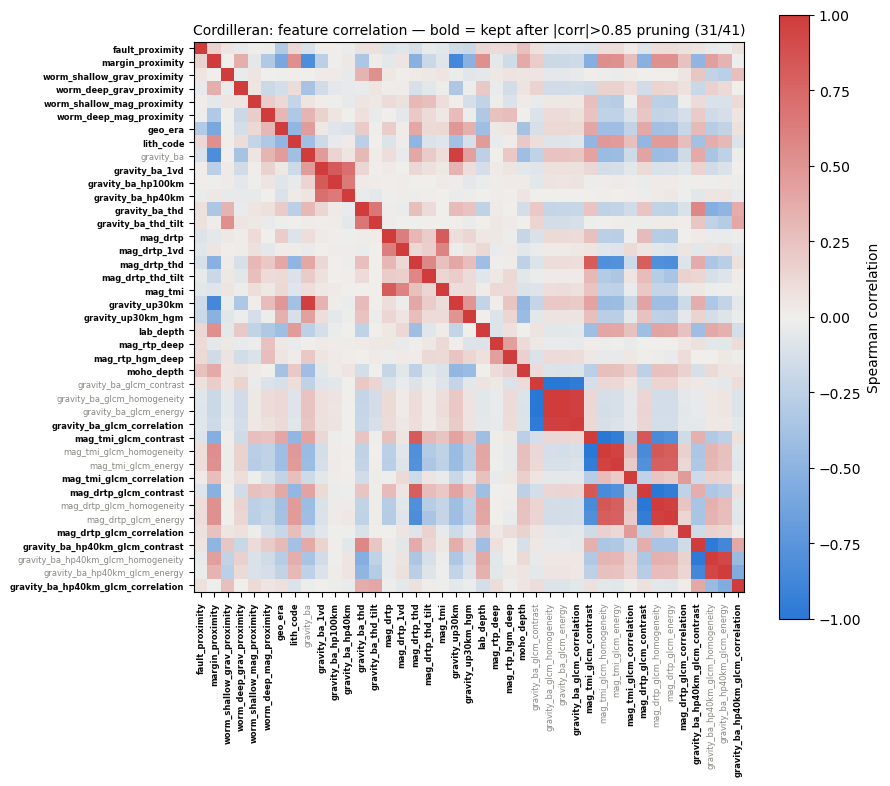

  [Cordilleran] collinearity pruning: 41 -> 31 features
  model_cfg = {'hidden': 64, 'dropout': 0.3, 'weight_decay': 0.0001}
  [Cordilleran] DevNet eval (full+pruned ablation) ≈ (n_repeats*5 + 5) * restarts * n_losses * 2 feature sets = 700 次训练
  -- RF [full, 41 feats] --
    pooled OOF (5-fold):        AUC=0.970  AP=0.633
    repeated pooled OOF (5x6): median AUC=0.969  95% CI=[0.960, 0.977]
  -- RF [pruned, 31 feats] --
    pooled OOF (5-fold):        AUC=0.973  AP=0.594
    repeated pooled OOF (5x6): median AUC=0.972  95% CI=[0.964, 0.978]
  -- DevNet(deviation) [full, 41 feats] --
    pooled OOF (5-fold):        AUC=0.948  AP=0.473
    repeated pooled OOF (5x6): median AUC=0.947  95% CI=[0.940, 0.955]
  -- DevNet(deviation) [pruned, 31 feats] --
    pooled OOF (5-fold):        AUC=0.957  AP=0.482
    repeated pooled OOF (5x6): median AUC=0.952  95% CI=[0.948, 0.957]
  -- DevNet(ranking) [full, 41 feats] --
    pooled OOF (5-fold):        AUC=0.967  AP=0.533
    repeated pooled OOF 

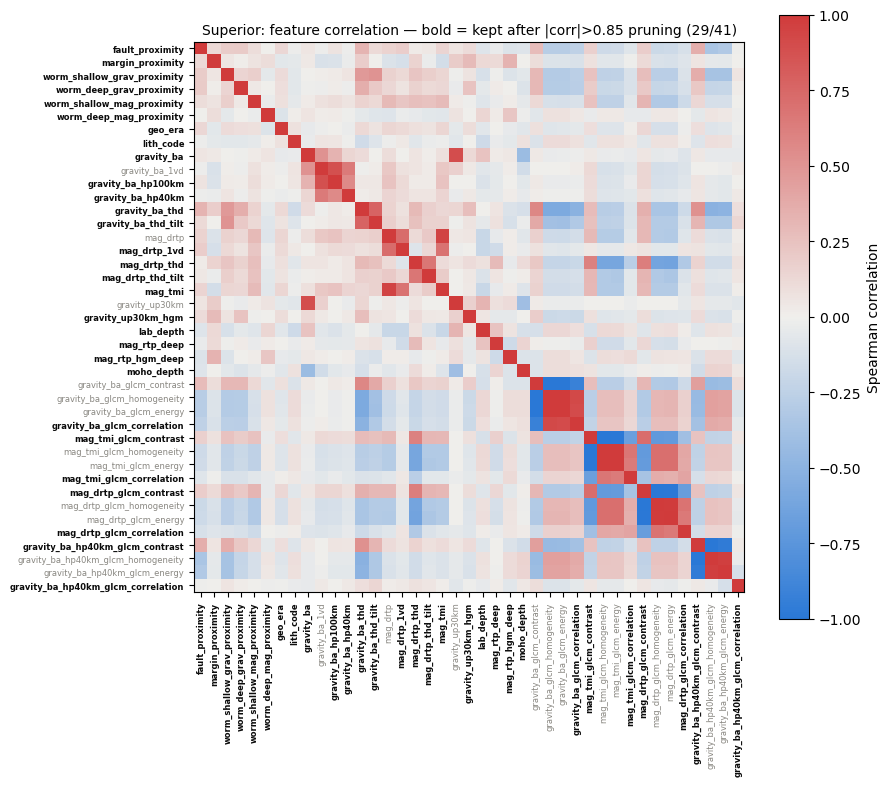

  [Superior] collinearity pruning: 41 -> 29 features
  model_cfg = {'hidden': 32, 'dropout': 0.4, 'weight_decay': 0.001}
  [Superior] DevNet eval (full+pruned ablation) ≈ (n_repeats*5 + 5) * restarts * n_losses * 2 feature sets = 700 次训练
  -- RF [full, 41 feats] --
    pooled OOF (5-fold):        AUC=0.893  AP=0.154
    repeated pooled OOF (5x6): median AUC=0.925  95% CI=[0.890, 0.945]
  -- RF [pruned, 29 feats] --
    pooled OOF (5-fold):        AUC=0.941  AP=0.178
    repeated pooled OOF (5x6): median AUC=0.932  95% CI=[0.917, 0.945]
  -- DevNet(deviation) [full, 41 feats] --
    pooled OOF (5-fold):        AUC=0.899  AP=0.158
    repeated pooled OOF (5x6): median AUC=0.894  95% CI=[0.845, 0.934]
  -- DevNet(deviation) [pruned, 29 feats] --
    pooled OOF (5-fold):        AUC=0.844  AP=0.194
    repeated pooled OOF (5x6): median AUC=0.891  95% CI=[0.845, 0.938]
  -- DevNet(ranking) [full, 41 feats] --
    pooled OOF (5-fold):        AUC=0.877  AP=0.247
    repeated pooled OOF (5x6): 

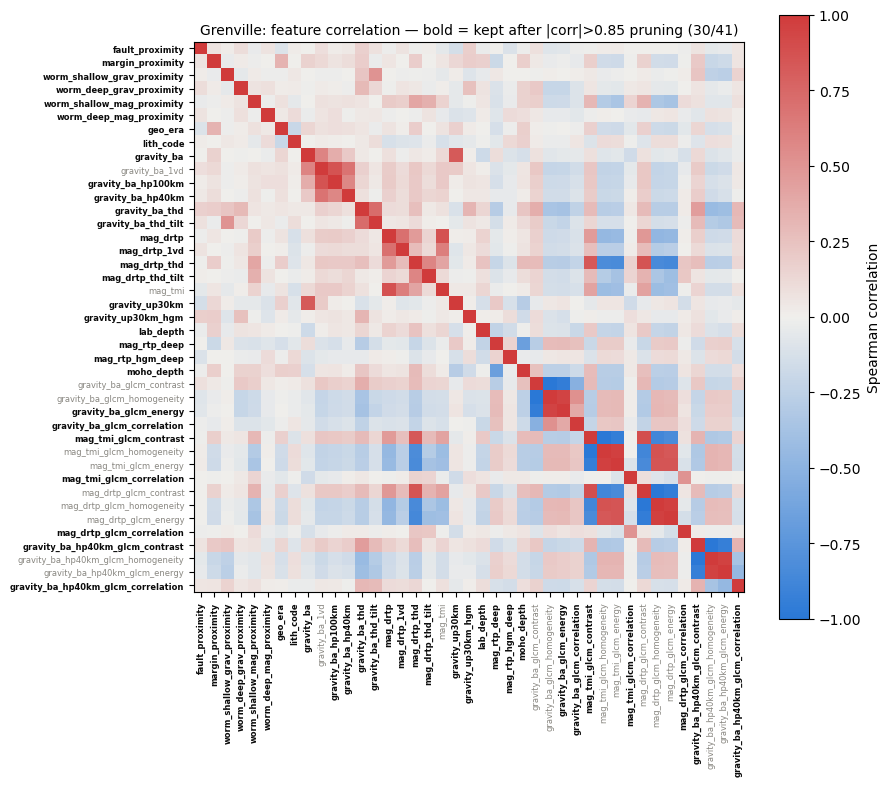

  [Grenville] collinearity pruning: 41 -> 30 features
  model_cfg = {'hidden': 32, 'dropout': 0.4, 'weight_decay': 0.001}
  [Grenville] DevNet eval (full+pruned ablation) ≈ (n_repeats*5 + 5) * restarts * n_losses * 2 feature sets = 700 次训练
  -- RF [full, 41 feats] --
    pooled OOF (5-fold):        AUC=0.641  AP=0.019
    repeated pooled OOF (5x6): median AUC=0.666  95% CI=[0.592, 0.726]
  -- RF [pruned, 30 feats] --
    pooled OOF (5-fold):        AUC=0.799  AP=0.042
    repeated pooled OOF (5x6): median AUC=0.787  95% CI=[0.766, 0.842]
  -- DevNet(deviation) [full, 41 feats] --
    pooled OOF (5-fold):        AUC=0.443  AP=0.009
    repeated pooled OOF (5x6): median AUC=0.483  95% CI=[0.432, 0.493]
  -- DevNet(deviation) [pruned, 30 feats] --
    pooled OOF (5-fold):        AUC=0.630  AP=0.016
    repeated pooled OOF (5x6): median AUC=0.585  95% CI=[0.564, 0.626]
  -- DevNet(ranking) [full, 41 feats] --
    pooled OOF (5-fold):        AUC=0.394  AP=0.007
    repeated pooled OOF (5x6)

In [13]:
# Build worm trees once (shared across all regions)
print('Building worm KDTrees ...')
_worm_cfg  = list(REGIONS.values())[0]['worms']
WORM_TREES = build_worm_trees(_worm_cfg)

REGION_PTS   = {}
REGION_FEATS = {}   # name -> pruned (collinearity-reduced) feature list
RESULTS      = {}   # name -> model -> feature_set('full'/'pruned') -> metrics
TRAINED      = {}   # name -> production models for prediction maps (pruned features)

for name in RUN_REGIONS:
    cfg = REGIONS[name]
    print(f'\n{"="*70}\n[{name}]\n{"="*70}')
    raster_cols = list(CLIPPED_RASTERS[name].keys())
    pts = build_region(name, cfg, WORM_TREES)
    REGION_PTS[name] = pts

    X_full_raw, y, feat_cols_full = get_raw_features(pts, raster_cols)
    print(f'  n={len(y)}  positives={int(y.sum())}  full features={len(feat_cols_full)}')

    pruned_cols = prune_collinear(pts, feat_cols_full, thresh=COLLINEARITY_THRESH)
    REGION_FEATS[name] = pruned_cols
    plot_collinearity_heatmap(pts, feat_cols_full, pruned_cols, name, thresh=COLLINEARITY_THRESH)
    X_pruned_raw, _, feat_cols_pruned = get_raw_features(pts, raster_cols, feat_subset=pruned_cols)
    print(f'  [{name}] collinearity pruning: {len(feat_cols_full)} -> {len(feat_cols_pruned)} features')

    model_cfg = REGION_MODEL_CFG.get(name, DEFAULT_MODEL_CFG)
    n_train_est = (CV_N_REPEATS * CV_N_SPLITS + CV_N_SPLITS) * DN_RESTARTS * len(RUN_LOSSES) * 2
    print(f'  model_cfg = {model_cfg}')
    print(f'  [{name}] DevNet eval (full+pruned ablation) ≈ (n_repeats*5 + 5) * restarts'
          f' * n_losses * 2 feature sets = {n_train_est} 次训练')

    RESULTS[name] = {}
    feature_sets = {'full': (X_full_raw, feat_cols_full), 'pruned': (X_pruned_raw, feat_cols_pruned)}
    model_list = [('RF', rf_fold_scorer)] + [
        (f'DevNet({lt})', devnet_fold_scorer_factory(lt, model_cfg=model_cfg))
        for lt in RUN_LOSSES
    ]
    for model_name, scorer in model_list:
        RESULTS[name][model_name] = {}
        for fs_name, (X_fs, cols_fs) in feature_sets.items():
            print(f'  -- {model_name} [{fs_name}, {len(cols_fs)} feats] --')
            auc_oof, ap_oof, _ = pooled_oof_eval(X_fs, y, scorer)
            print(f'    pooled OOF (5-fold):        AUC={auc_oof:.3f}  AP={ap_oof:.3f}')
            rep_aucs = repeated_pooled_auc(X_fs, y, scorer)
            med, lo, hi = np.median(rep_aucs), *np.percentile(rep_aucs, [2.5, 97.5])
            print(f'    repeated pooled OOF (5x{CV_N_REPEATS}): median AUC={med:.3f}  95% CI=[{lo:.3f}, {hi:.3f}]')
            RESULTS[name][model_name][fs_name] = {
                'n_features': len(cols_fs),
                'oof_auc': auc_oof, 'oof_ap': ap_oof,
                'rep_aucs': rep_aucs, 'rep_median': med, 'rep_ci': (lo, hi),
            }

    # ── Production models: PRUNED feature set only, fit on ALL of this
    #    region's data. RF and DevNet use the identical pruned set. ────────
    X_all, y_all, feat_cols_fm, scaler, imputer = feature_matrix(
        pts, raster_cols, feat_subset=pruned_cols)
    rf_pipeline = make_rf_pipeline()
    rf_pipeline.fit(X_pruned_raw, y)  # Pipeline handles its own impute/scale internally

    # DevNet production = DN_RESTARTS-model ensemble (rank-averaged), matching
    # the evaluation protocol above -- not a single model.
    dn_ensemble, dn_losses = [], []
    for k in range(DN_RESTARTS):
        record = (k == 0)
        m, losses = train_devnet(X_all, y_all, LOSS_TYPE, seed=DN_SEED + k,
                                 model_cfg=model_cfg, record_losses=record)
        dn_ensemble.append(m)
        if record:
            dn_losses = losses

    TRAINED[name] = {
        'pts': pts, 'feat_cols': feat_cols_pruned, 'raster_cols': raster_cols,
        'rf_model':  rf_pipeline.named_steps['rf'],
        'rf_scaler': rf_pipeline.named_steps['scaler'],
        'rf_imp':    rf_pipeline.named_steps['imputer'],
        'dn_ensemble': dn_ensemble, 'dn_scaler': scaler, 'dn_imp': imputer,
        'dn_losses': dn_losses, 'model_cfg': model_cfg,
    }
    print(f'[{name}] evaluation + production fit complete (production uses pruned features).')

print(f'\nRegions evaluated: {RUN_REGIONS}  |  Losses: {RUN_LOSSES}')
print('Pruned feature sets in REGION_FEATS, results in RESULTS, production models in TRAINED.')


## 10. DevNet Training Loss Curve (production model)

Loss curve for the first member of the final full-data DevNet ensemble
(`LOSS_TYPE`, seed=`DN_SEED`) trained per region in Section 9 — the
corrected deviation loss (or ranking loss) should show smooth, monotonic-ish
convergence rather than the noisy trace produced by resampling the reference
distribution every batch. The other `DN_RESTARTS - 1` ensemble members are
trained identically (different seeds) but without recording their loss
history.


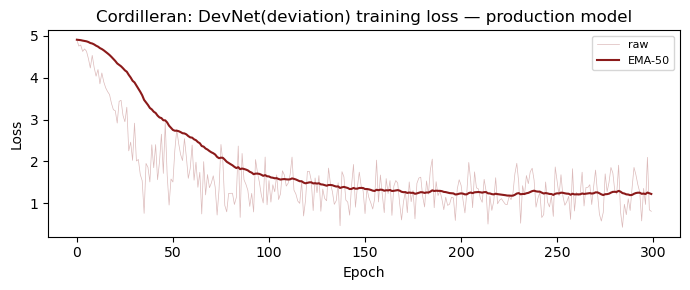

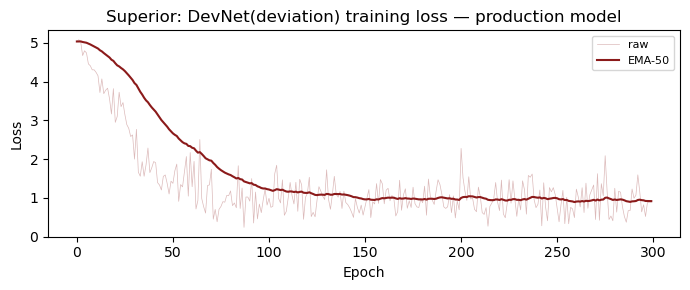

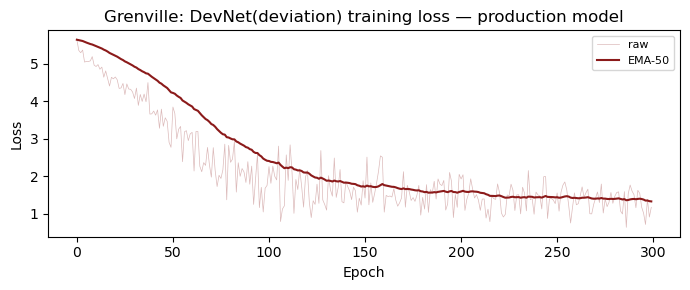

In [14]:
for name, t in TRAINED.items():
    losses = t['dn_losses']
    alpha = 2 / (50 + 1)
    ema = [losses[0]]
    for l in losses[1:]:
        ema.append(alpha * l + (1 - alpha) * ema[-1])
    fig, ax = plt.subplots(figsize=(7, 3))
    ax.plot(losses, lw=0.5, alpha=0.3, color='#8b1a1a', label='raw')
    ax.plot(ema,    lw=1.5, color='#8b1a1a', label='EMA-50')
    ax.set_xlabel('Epoch'); ax.set_ylabel('Loss')
    ax.set_title(f'{name}: DevNet({LOSS_TYPE}) training loss — production model')
    ax.legend(fontsize=8); plt.tight_layout(); plt.show()


## 11. Comparison Table

Full-feature vs. pruned-feature ablation: for every region in `RUN_REGIONS`
and every model (`RF` plus one row per `RUN_LOSSES` entry), both the original
full feature set and the `prune_collinear`-reduced set are evaluated under
the identical pooled-OOF / repeated-CV protocol from Section 6 -- pruning is
never silently substituted in without a side-by-side comparison. With
`FAST_MODE=True` the table only ever has the region(s)/loss(es) that were
actually evaluated, so it never indexes a combination that was never
computed.


In [15]:
active_models = ['RF'] + [f'DevNet({lt})' for lt in RUN_LOSSES]
feature_set_names = ['full', 'pruned']

rows = []
for name in RUN_REGIONS:
    for model_name in active_models:
        for fs_name in feature_set_names:
            r = RESULTS[name][model_name][fs_name]
            rows.append({
                'region': name,
                'model': model_name,
                'feature_set': fs_name,
                'n_features': r['n_features'],
                'pooled_oof_auc': r['oof_auc'],
                'pooled_oof_ap':  r['oof_ap'],
                'repeatedCV_median_auc': r['rep_median'],
                'repeatedCV_ci_lo': r['rep_ci'][0],
                'repeatedCV_ci_hi': r['rep_ci'][1],
            })
comparison_df = pd.DataFrame(rows)

pd.set_option('display.width', 160)
print('Full vs. pruned feature-set ablation (pooled OOF / repeated-CV):')
print(comparison_df.round(3).to_string(index=False))


Full vs. pruned feature-set ablation (pooled OOF / repeated-CV):
     region             model feature_set  n_features  pooled_oof_auc  pooled_oof_ap  repeatedCV_median_auc  repeatedCV_ci_lo  repeatedCV_ci_hi
Cordilleran                RF        full          41           0.970          0.633                  0.969             0.960             0.977
Cordilleran                RF      pruned          31           0.973          0.594                  0.972             0.964             0.978
Cordilleran DevNet(deviation)        full          41           0.948          0.473                  0.947             0.940             0.955
Cordilleran DevNet(deviation)      pruned          31           0.957          0.482                  0.952             0.948             0.957
Cordilleran   DevNet(ranking)        full          41           0.967          0.533                  0.952             0.947             0.969
Cordilleran   DevNet(ranking)      pruned          31           0.966  

## 12. Prediction Map

Reuses the original notebook's grid-building and panel-plotting code
unchanged. DevNet scoring now calls `ensemble_score(dn_ensemble, ...)` — the
same `DN_RESTARTS`-model rank-averaged ensemble used during evaluation —
instead of a single model, so the map reflects the model that was actually
evaluated. RF is unchanged (a single `Pipeline` fit; RF is already an
internal ensemble and stable across seeds). Both models score the grid using `TRAINED[name]['feat_cols']`, which is the region's *pruned* feature set (`REGION_FEATS[name]`) -- the same one used for evaluation and production training, so training and the prediction map are never on different feature sets.


In [16]:
from scipy.interpolate import griddata as _griddata
from rasterio.transform import Affine as _Affine
from rasterio.features import geometry_mask as _geomask
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches

_PROSP_COLORS = ["#1a6faf", "#42c4e8", "#f5e21a", "#d73027"]


def _draw_bnd(ax, bnd_proj):
    """Draw boundary without triggering geopandas autoscale."""
    for geom in bnd_proj.geometry:
        polys = [geom] if geom.geom_type == 'Polygon' else list(geom.geoms)
        for poly in polys:
            xs, ys = poly.exterior.xy
            ax.plot(xs, ys, 'k-', lw=1.2)


def _prosp_panel(ax, proba, xs_p, ys_p, bnd_proj, dep_proj, model_name):
    """P90/P95/P99 upper-tail classification panel."""
    valid = proba[np.isfinite(proba)]

    bx0, by0, bx1, by1 = bnd_proj.total_bounds
    res = 5000

    y_range = np.arange(by1, by0, -res)
    x_range = np.arange(bx0, bx1,  res)
    Xi, Yi  = np.meshgrid(x_range, y_range)

    Z   = _griddata(np.column_stack([xs_p, ys_p]), proba, (Xi, Yi), method='linear')
    tfm = _Affine.translation(bx0, by1) * _Affine.scale(res, -res)
    msk = _geomask(bnd_proj.geometry, out_shape=Z.shape, transform=tfm, invert=True)
    Z   = np.where(msk, Z, np.nan)

    ext  = [bx0, bx1, by0, by1]
    bks  = [0.0,
            float(np.percentile(valid, 90)),
            float(np.percentile(valid, 95)),
            float(np.percentile(valid, 99)), 1.0]
    cmap = mcolors.ListedColormap(_PROSP_COLORS)
    norm = mcolors.BoundaryNorm(bks, len(_PROSP_COLORS))

    ax.imshow(np.ma.masked_invalid(Z), extent=ext, origin='upper',
              cmap=cmap, norm=norm, aspect='equal', alpha=0.92)
    ax.set_xlim(bx0, bx1); ax.set_ylim(by0, by1)
    _draw_bnd(ax, bnd_proj)
    ax.scatter(dep_proj.geometry.x, dep_proj.geometry.y,
               c='red', s=120, marker='*', alpha=0.6, zorder=5,
               linewidths=0.4, edgecolors='darkred')

    pct = [0, 85, 90, 95, 100]
    patches = [mpatches.Patch(facecolor=_PROSP_COLORS[i], edgecolor='grey', lw=0.5,
               label=f'P{pct[i]}-P{pct[i+1]} ({bks[i]:.4f}-{bks[i+1]:.4f})')
               for i in range(4)]
    patches.append(plt.Line2D([0], [0], marker='*', color='w',
                               markerfacecolor='red', markersize=11,
                               alpha=0.7, label='Known REE'))
    ax.legend(handles=patches, loc='lower right', fontsize=8,
              title=model_name, title_fontsize=8, framealpha=0.9)
    ax.set_title(model_name, fontsize=11, fontweight='bold')
    ax.set_xlabel('Easting (m)');  ax.set_ylabel('Northing (m)')
    ax.grid(True, alpha=0.25)
    ax.set_xlim(bx0, bx1);  ax.set_ylim(by0, by1)


def build_grid(cfg):
    """Regular prediction grid within the study area (EPSG:4326)."""
    boundary   = gpd.read_file(cfg['outline']).to_crs('EPSG:4326')
    study_area = boundary.unary_union
    xmin, ymin, xmax, ymax = boundary.total_bounds
    xs = np.arange(xmin, xmax, GRID_DEG)
    ys = np.arange(ymin, ymax, GRID_DEG)
    xx, yy = np.meshgrid(xs, ys)
    gdf = gpd.GeoDataFrame(
        geometry=gpd.points_from_xy(xx.ravel(), yy.ravel()), crs='EPSG:4326')
    gdf = gdf[gdf.within(study_area)].copy().reset_index(drop=True)
    gdf['lat'] = gdf.geometry.y
    gdf['lon'] = gdf.geometry.x
    return gdf, boundary


def predict_grid(cfg, name, rf_model, rf_scaler, rf_imputer, feat_cols,
                 dn_ensemble, dn_scaler, dn_imputer, worm_trees):
    print(f'[{name}] building prediction grid ...')
    grid, boundary = build_grid(cfg)

    pts = pd.DataFrame({'lat': grid['lat'], 'lon': grid['lon']})
    pts = add_terrane_h3(pts, CLIPPED_VECTORS[name].get('h3_grid'))
    pts = add_proximity_lines(pts, cfg['faults'],  'fault')
    pts = add_proximity_lines(pts, cfg['margins'], 'margin')
    pts = add_proximity_worms(pts, worm_trees)
    pts = add_rasters(pts, CLIPPED_RASTERS[name])

    print(f'  extracting GLCM texture features for prediction grid ...')
    pts = add_glcm_features(pts, CLIPPED_RASTERS[name])

    X = pts.reindex(columns=feat_cols).astype(float).values

    X_rf     = rf_scaler.transform(rf_imputer.transform(X))
    rf_proba = rf_model.predict_proba(X_rf)[:, 1]

    X_dn = dn_scaler.transform(dn_imputer.transform(X))
    dn_proba = ensemble_score(dn_ensemble, X_dn)  # rank-averaged ensemble, already ~[0, 1]

    grid['rf_proba'] = rf_proba
    grid['dn_proba'] = dn_proba
    grid.to_file(f'{name}_prospectivity_no_geochem.geojson', driver='GeoJSON')
    print(f'  saved → {name}_prospectivity_no_geochem.geojson')

    grid_proj = gpd.GeoDataFrame(
        geometry=gpd.points_from_xy(grid['lon'], grid['lat']), crs='EPSG:4326'
    ).to_crs(PROJECTED_CRS)
    xs_p = grid_proj.geometry.x.values
    ys_p = grid_proj.geometry.y.values

    bnd_proj = boundary.to_crs(PROJECTED_CRS)
    dep      = pd.read_csv(cfg['dep']).dropna(subset=['Latitude', 'Longitude'])
    dep_gdf  = gpd.GeoDataFrame(
        dep,
        geometry=gpd.points_from_xy(dep['Longitude'], dep['Latitude']),
        crs='EPSG:4326',
    ).to_crs(PROJECTED_CRS)
    dep_in   = dep_gdf[dep_gdf.within(bnd_proj.unary_union)]

    # Adapt figure size to each region's geographic aspect ratio
    bx0, by0, bx1, by1 = bnd_proj.total_bounds
    _gw = bx1 - bx0;  _gh = by1 - by0  # metres
    _ph = 14  # panel height (inches, fixed)
    _pw = max(min(_ph * _gw / _gh, 14), 5)  # panel width, clamped 5–14""
    fig, axes = plt.subplots(1, 2, figsize=(_pw * 2 + 2, _ph + 1),
                             constrained_layout=True)
    fig.suptitle(f'{name} — REE Prospectivity (EPSG:3978)',
                 fontsize=14, fontweight='bold')
    _prosp_panel(axes[0], rf_proba, xs_p, ys_p, bnd_proj, dep_in, 'Random Forest')
    _prosp_panel(axes[1], dn_proba, xs_p, ys_p, bnd_proj, dep_in, 'DevNet (50% cosine negatives)')
    plt.show()
    return grid


### Generate prediction maps for regions in RUN_REGIONS


[Cordilleran] building prediction grid ...


  extracting GLCM texture features for prediction grid ...
    GLCM: gravity_ba → 4 texture features
    GLCM: mag_tmi → 4 texture features
    GLCM: mag_drtp → 4 texture features
    GLCM: gravity_ba_hp40km → 4 texture features
  saved → Cordilleran_prospectivity_no_geochem.geojson


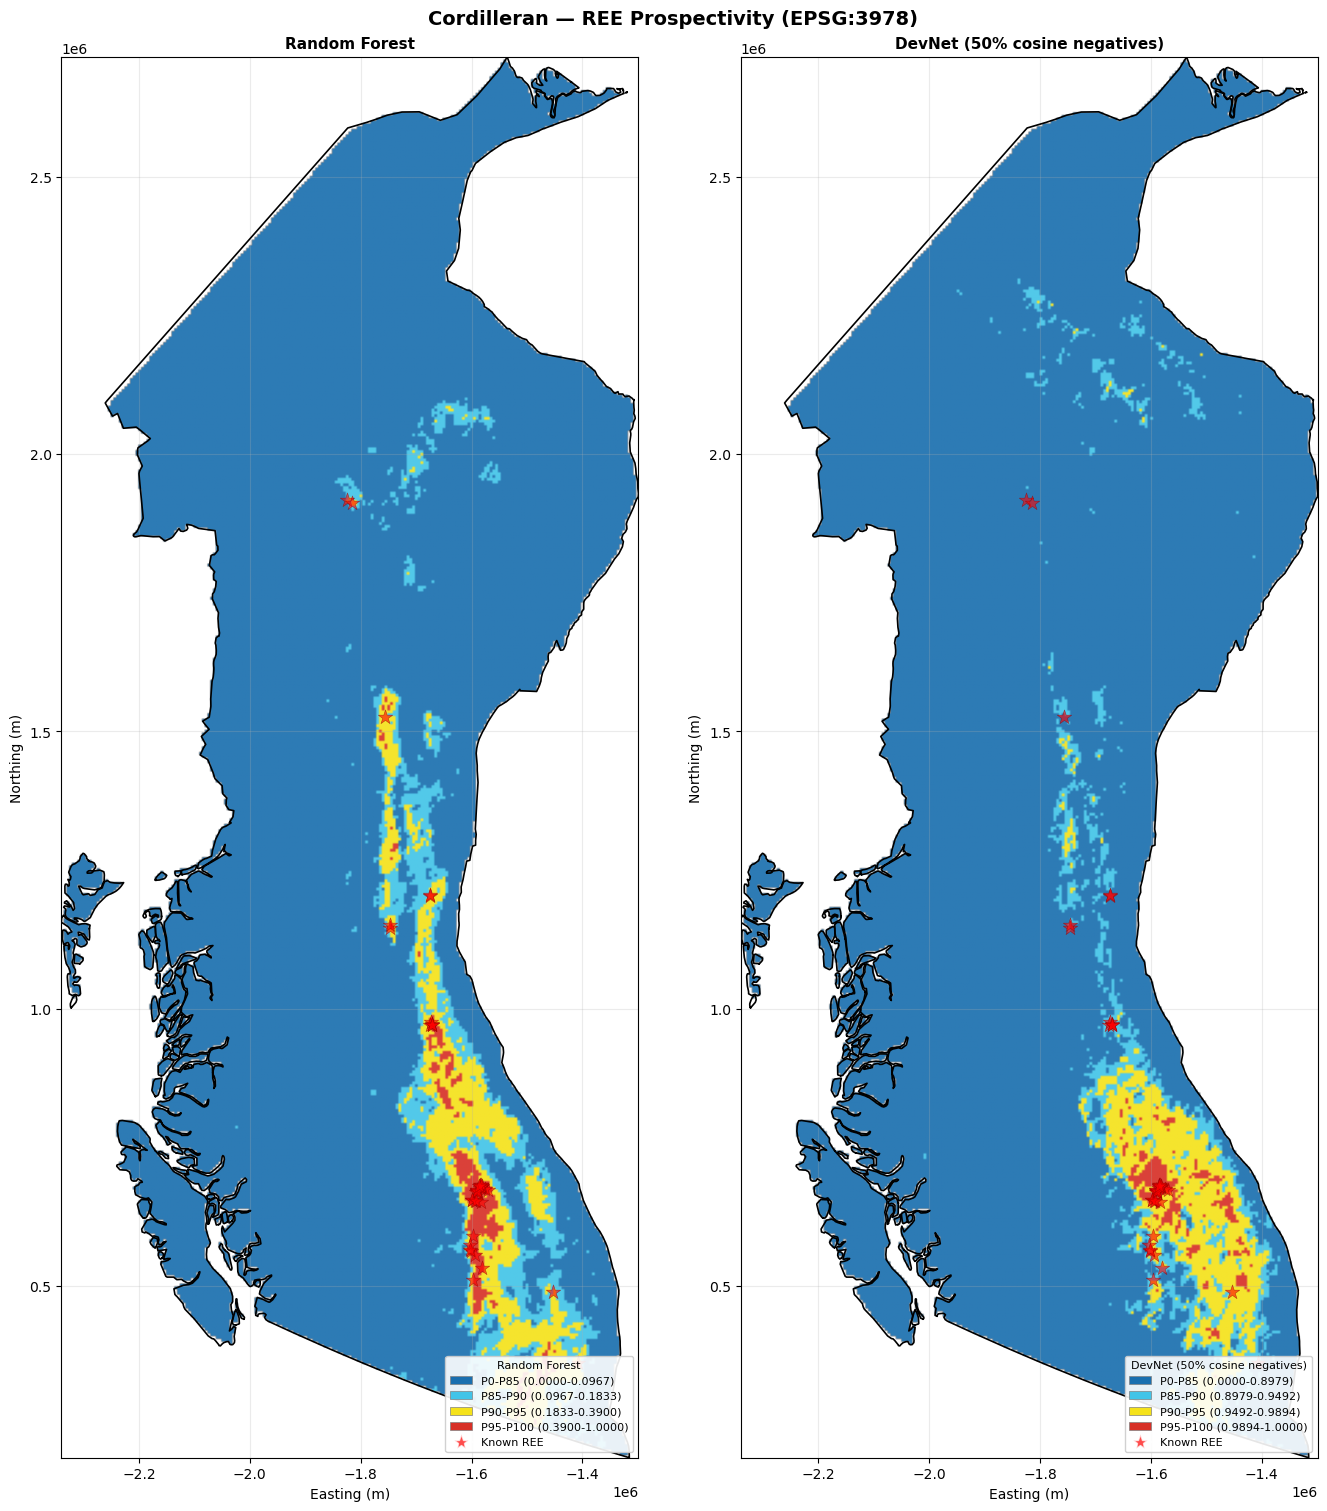

[Superior] building prediction grid ...
  extracting GLCM texture features for prediction grid ...
    GLCM: gravity_ba → 4 texture features
    GLCM: mag_tmi → 4 texture features
    GLCM: mag_drtp → 4 texture features
    GLCM: gravity_ba_hp40km → 4 texture features
  saved → Superior_prospectivity_no_geochem.geojson


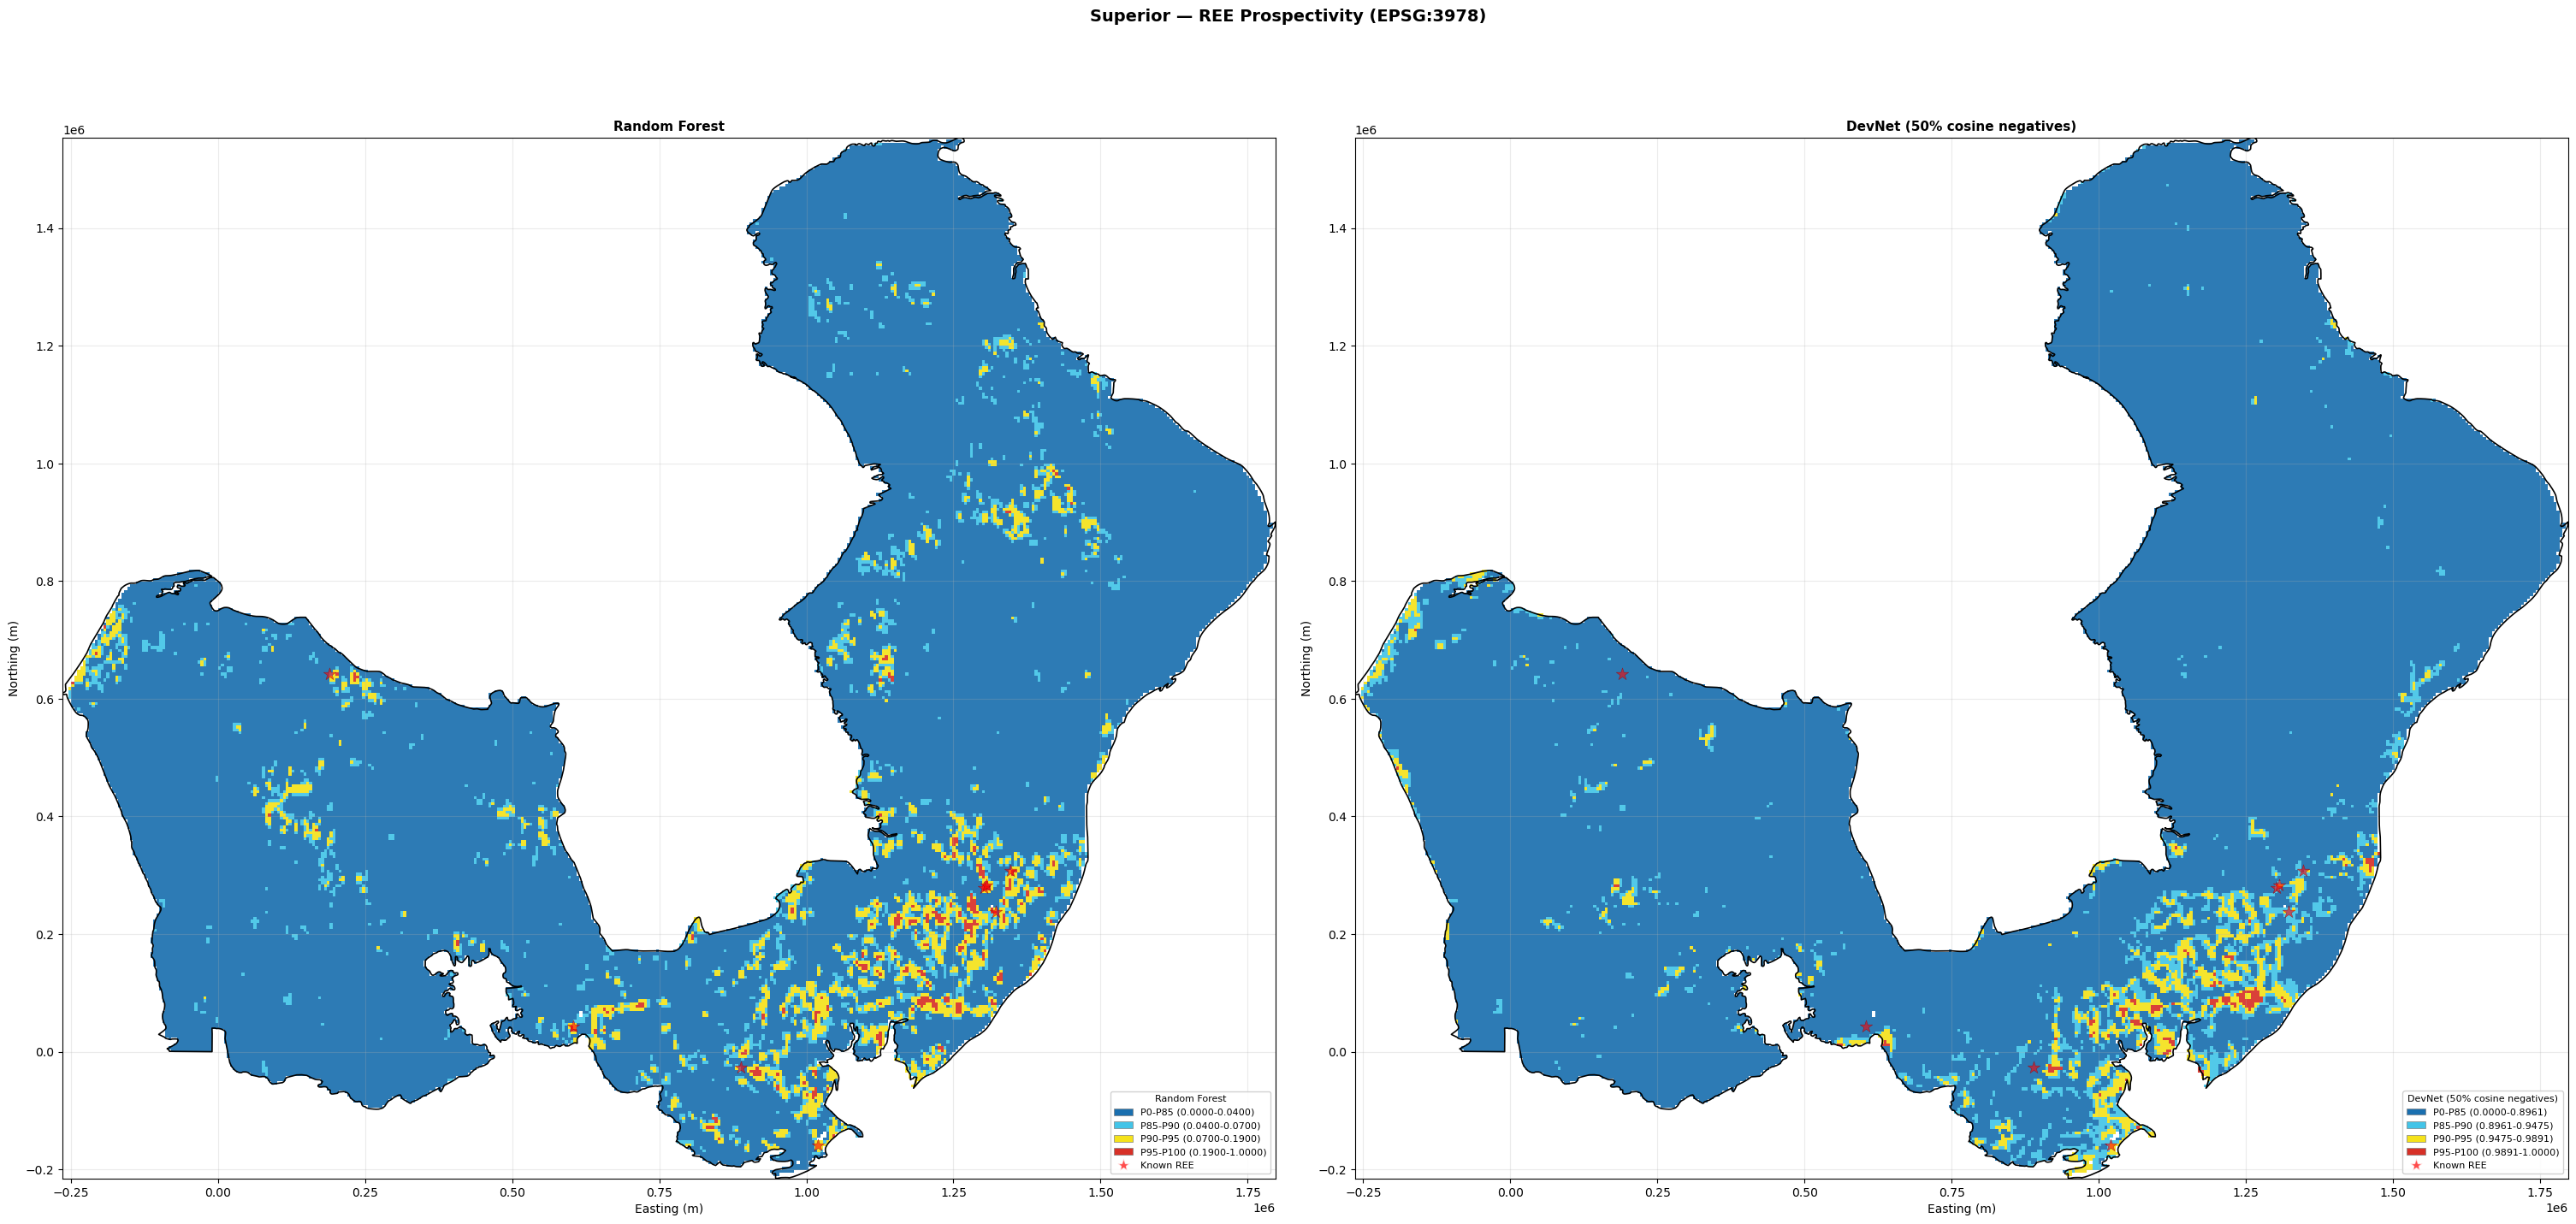

[Grenville] building prediction grid ...
  extracting GLCM texture features for prediction grid ...
    GLCM: gravity_ba → 4 texture features
    GLCM: mag_tmi → 4 texture features
    GLCM: mag_drtp → 4 texture features
    GLCM: gravity_ba_hp40km → 4 texture features
  saved → Grenville_prospectivity_no_geochem.geojson


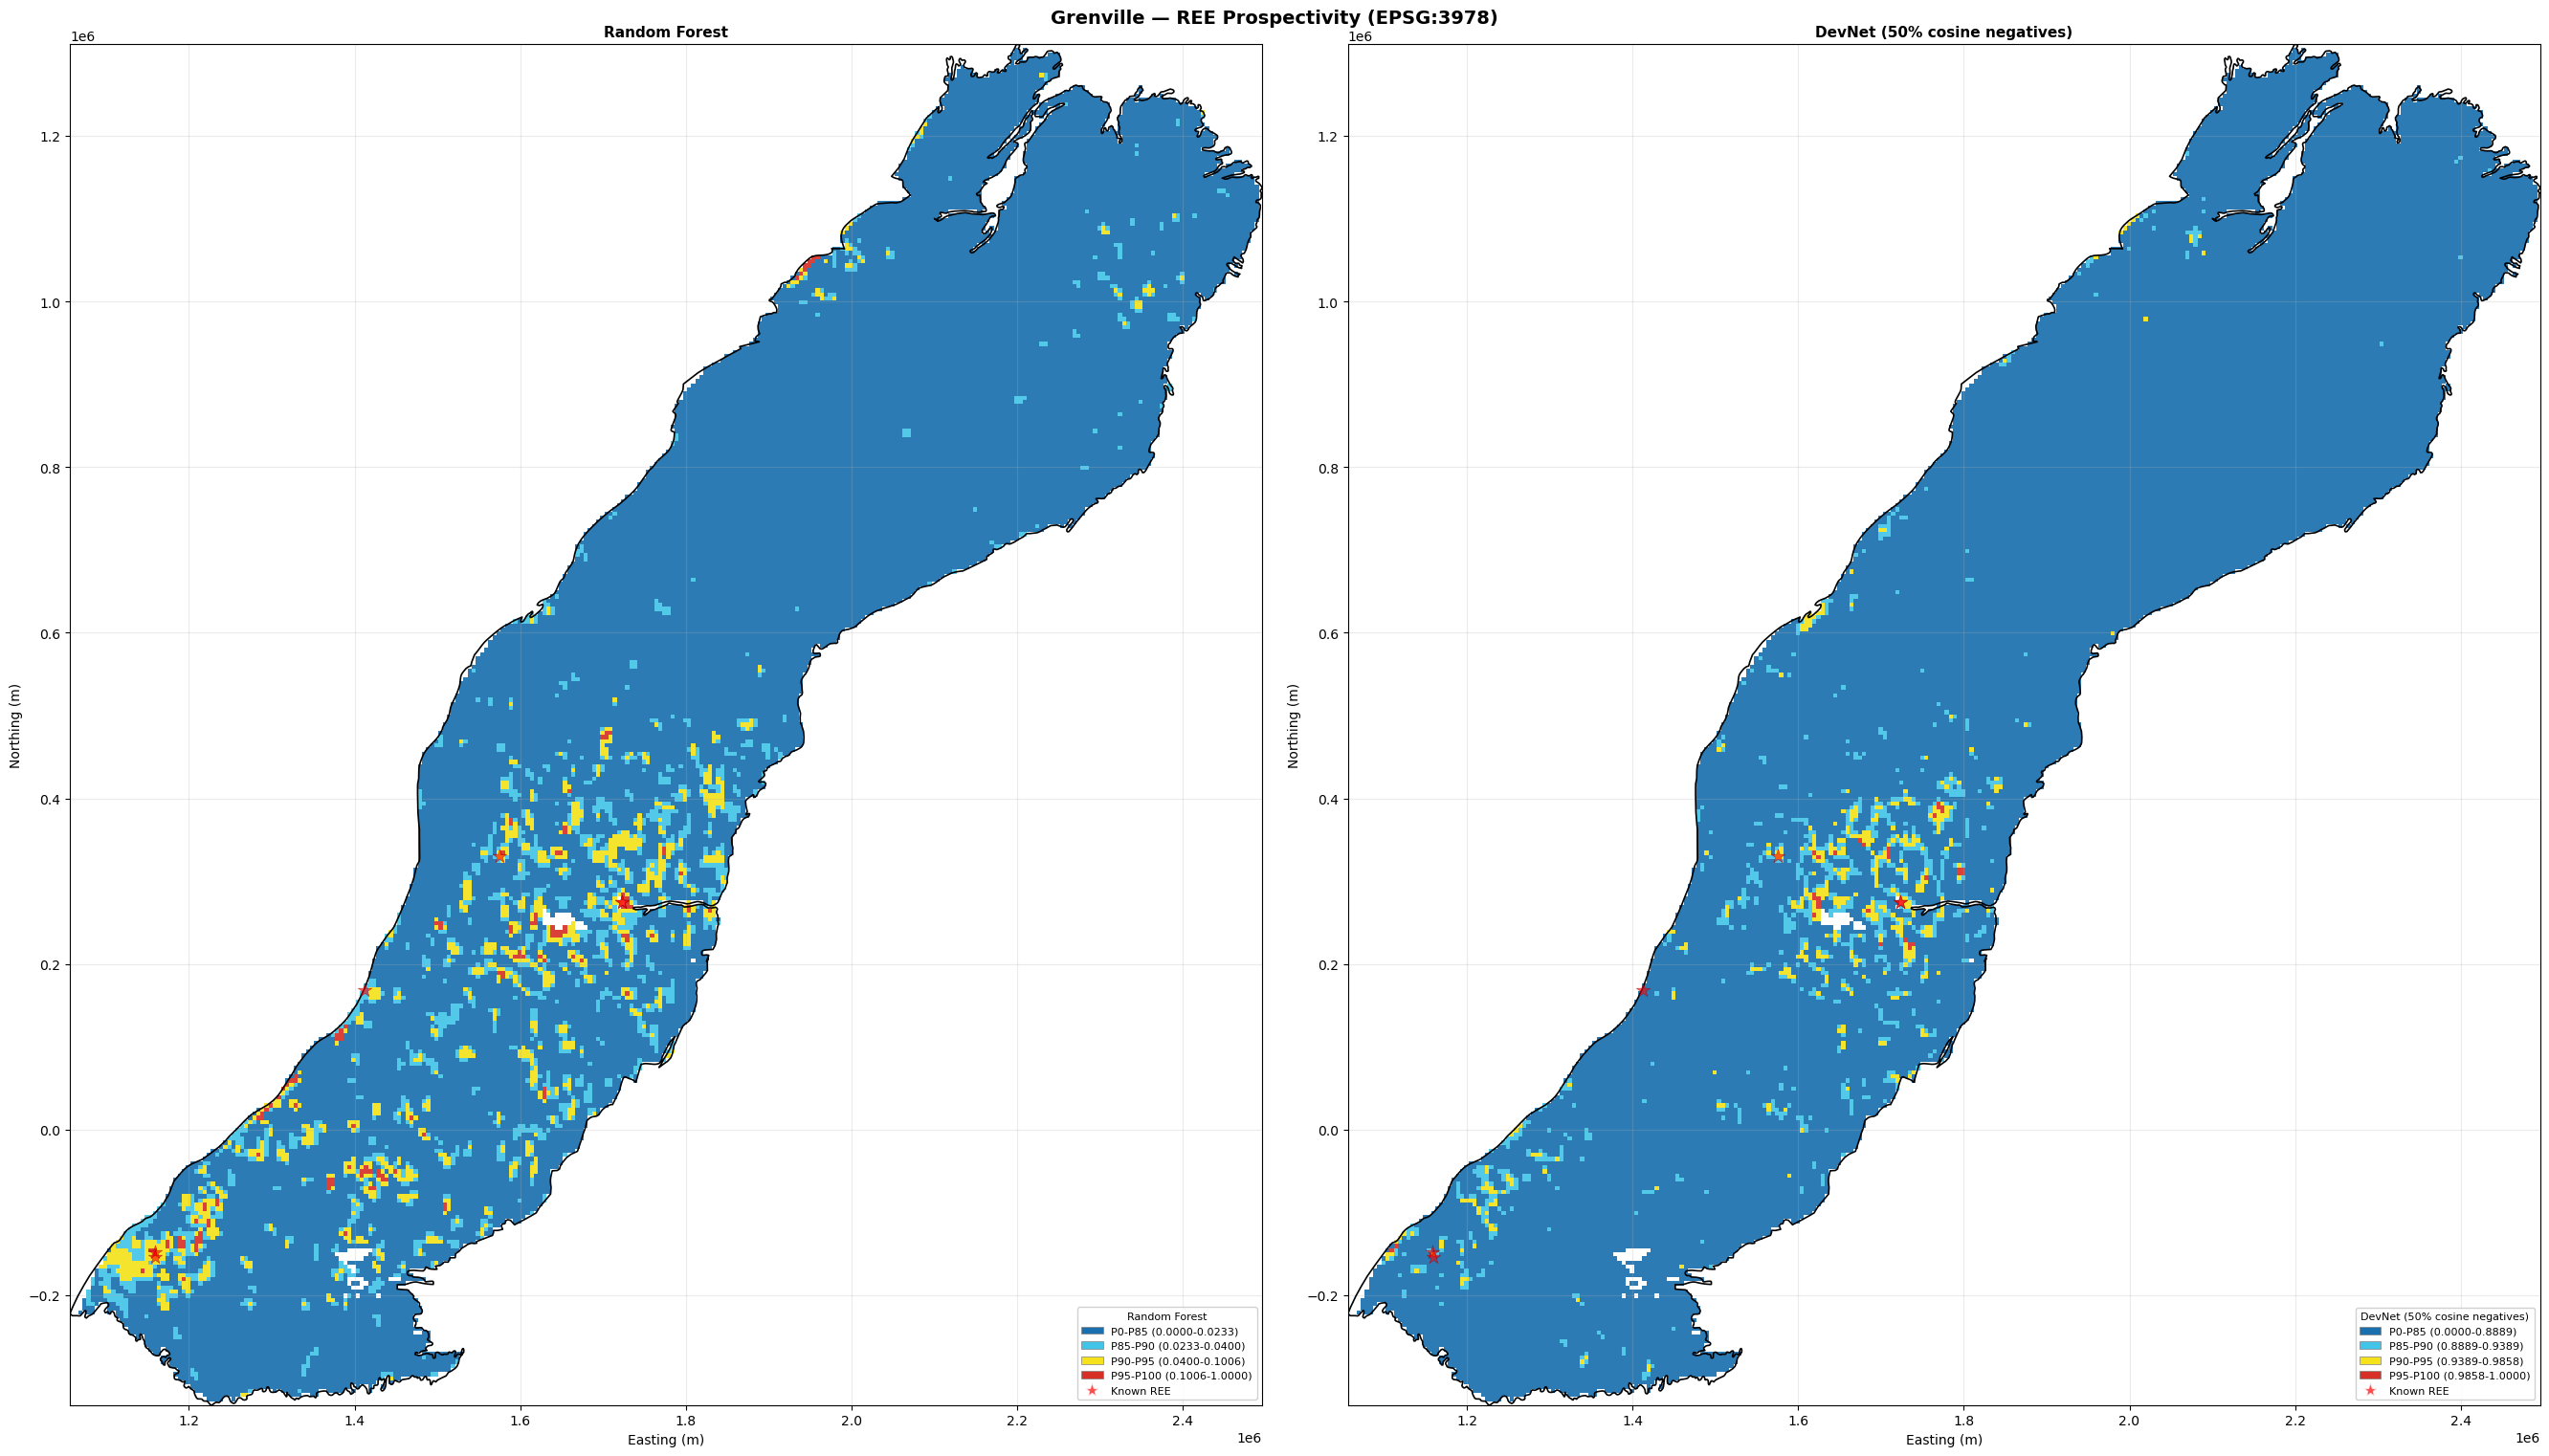

In [17]:
for name in RUN_REGIONS:
    cfg = REGIONS[name]
    t = TRAINED[name]
    grid = predict_grid(
        cfg, name,
        t['rf_model'], t['rf_scaler'], t['rf_imp'], t['feat_cols'],
        t['dn_ensemble'], t['dn_scaler'], t['dn_imp'],
        WORM_TREES,
    )
    TRAINED[name]['grid'] = grid
